# Where Yes and No Become Maybe
### The nested partner ring, traced route by route

Dean A. Kulik, QuHarmonics Research Group, ORCID 0009-0003-3128-8828. Executed notebook for the paper of the same name, October 2026.

Every route below is written as the algorithm that walked it. The predictions were sealed with SHA-256 before any check was run; the seal texts sit next to this notebook and their hashes are printed in the first cell. Ledger words: **STANDS** (supplied by a theorem or measured fact), **RUNS** (the route computed the landing before the data was linked), **DEAD END** (ran, landed elsewhere, routed to its owner), **OPEN** (sealed, a chain link not yet written), **PULL** (an interpretive bridge).

The object is Dean Kulik's nested ring. Partner rule: reverse a word, unless it is a palindrome, then complement it. Representatives (the smaller member of each pair) run in ascending order on one half of the circle, each partner faces its word across the circle, and the two words at the centre seam are swapped.

`two_bit_circle.xlsx` should sit next to this notebook for Route 1's cell-by-cell reproduction; every other cell is self-contained.

In [1]:
import hashlib, os, math, random, time
from fractions import Fraction as Fr
from functools import lru_cache
from math import isqrt
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display
os.makedirs('figures', exist_ok=True)
SEALS = {'seal_address.txt': "SEAL nested-ring address arithmetic, 2026-10-19, written before the checks below are run.\nSplit a rep of width L into its front half f, optional middle bit c, back half g (n = floor(L/2)).\nRep test: J(g) > f, or g = J(f) with f < 2^(n-1) (the palindromes with leading 0).\nA1 Even L = 2n: rank(f,g) = f(2^n - 1) - f(f-1)/2 + min(f, 2^(n-1)) + D_f(g) + [f < 2^(n-1)][J(f) < g],\n   D_f(g) = #{g' < g : J(g') > f}. Exact for every rep L = 2..16 and for random reps L <= 512.\nA2 Odd L = 2n+1: rank(f,c,g) = 2[f(2^n - 1) - f(f-1)/2 + min(f, 2^(n-1))] + c(2^n - 1 - f) + D_f(g) + [f < 2^(n-1)](c + [J(f) < g]).\nA3 Unrank: the front half comes from one integer square root of the quadratic, the back half bit by bit with an O(1)\n   count per bit. Matches engine word_at at every position L <= 14 and at random positions L <= 1024.\nA4 The radial reader reads the square root. For u in (0, 1/2): b_L(u) = bit k_L of tau(u) = 1 - sqrt(1 - 2u) whenever\n   k_L <= L/2 - 6. For u in (1/2, 1): b_L(u) = bit (L-1-k_L) of tau(1-u) whenever L-1-k_L <= L/2 - 6.\n   Agreement >= 95% over 3000 random samples with L in [24, 160].\nWay home: the same notebook.\n", 'seal_gradient.txt': 'SEAL nested-ring gradient, 2026-10-19, written before the checks below are run.\nDerivation (frame law, averaged): a word with value-prefix q and free tail is a rep with probability\nsum_h [q_h = 0] 2^-(h+1) + (deferral remainder) = 1 - mid(q). The rep density at value t is 1 - t.\nG1 Block law. For a prefix q of length p >= 1 with 2p <= L:\n   #{reps of width L with prefix q} = 2^(L-p) (1 - mid(q)) + 2^ceil((L-2p)/2) ([q_0 = 0] - 1/2).\nG2 Parabola. With t = a/2^L, rank(a) = a - a^2/2^(L+1) + O(2^(L/2)); max over reps of |rank/2^L - (t - t^2/2)| <= 2^(-L/2+1), L = 10..20.\n   Equivalently 1/2 - angle = (1 - t)^2 / 2: the seam sits where the density reaches zero.\nG3 Quarter turn. word_at(L, 2^(L-2)) / 2^L -> 1 - 1/sqrt(2); |difference| < 2^(-L/2+2) at L = 40, 80, 160.\nG4 Bit bias. In a rep, Pr(bit h = 1) -> 1/2 - 2^-(h+2) and Pr(bit L-1-h = 1) -> 1/2 + 2^-(h+2).\nG5 Centroid. Mean value of a rep -> 1/3 of 2^L; mean value of a partner -> 2/3.\nWay home: the same notebook; each line prints its measured error or pass count.\n', 'seal_merge.txt': "SEAL total maybe, 2026-10-19, written before the check below is run.\nM1 The merge of x with its partner is all grey (x xor P x = 1^L) exactly when x is a palindrome (the complement rule)\n   or x is an anti-palindrome, J(x) = C(x) (the two rules give the same partner). Count: 2^ceil(L/2) + [L even] 2^(L/2).\n   In the square these are the diagonal and the anti-diagonal.\nM2 Merged ring image: averaging each slice of word i with the same slice of its partner gives grey exactly on the\n   residual's ones; the ring of merged words is symmetric under the half turn.\nWay home: the same notebook.\n", 'seal_routes.txt': 'SEAL nested-ring routes, 2026-10-19, written before any check below is run.\nObjects. P_L(x) = reverse(x) unless x is a palindrome, then complement(x). Rep a = min(x, P x).\nRing R_L: reps ascending at positions 0..M-1, P(rep_i) at N-1-i, positions M-1 and M swapped (N = 2^L, M = N/2).\nTape T_L = R_L[0] R_L[1] ... R_L[N-1] (L*2^L slices). Sheet reading S_L = complement(reverse(T_L)).\nF(a) = min(1a1, P(1a1)) on reps.\n\nS1 Antipode. R_L[N-1-i] = P(R_L[i]) for every i. T_L[LN-1-p] = T_L[p] xor pal(word holding p).\n   S_L = T_L with every non-palindromic word complemented. S_2 = 00011011 (MSB counting); S_L is not MSB counting for L >= 3.\nS2 Frame law. x = b m c is a rep iff (b,c) = (0,1); or (0,0) and m <= Jm; or (1,1) and m < Jm; never (1,0).\n   Equivalently reps(L) = 0.W(L-2).1  disjoint-union  0.reps(L-2).0  disjoint-union  F(reps(L-2)). Holds L = 3..16.\nS3 Depth. #{reps of width L with depth >= t} = 2^(L-1-2t) for 1 <= t <= floor((L-1)/2); roots(L) = 3*2^(L-3) for L >= 3;\n   mean depth = (1 - 4^-floor((L-1)/2))/3.\nS4 Rays. Non-palindromic root: F^k(rho) = 1^k rho 1^k. Palindromic root: F^k(rho) = a_k X rev(a_k), a_k = first k bits of 0101...,\n   X = rho for even k, complement(rho) for odd k. A closed-form encoder/decoder built on these matches the engine on every word, L <= 12.\nS5 Attractors. Reversal rays go to angle 1/2. Complement rays go to value 1/3 and to angle 5/18 (rank(F^k(00))/2^L -> 5/18).\nS6 Merge. Sum over all x of weight(x xor P x) = floor(L/2)*2^L + L*2^ceil(L/2). Agreeing light slices = agreeing dark slices.\nS7 Light. Each tape holds exactly L*2^(L-1) ones. Partner half minus rep half = 2^ceil(L/2) ones.\nS8 Rolling stack (any cyclic tape s, window w_i(W)). w_i(W+1) = 2^W s_i + w_(i+1)(W) = 2 w_i(W) + s_(i+W).\n   On the sheet: G_r(W) = B_(r+3)(W); G_0(W) = B_0(W+3); fills travel with values.\n   Nibble law: low nibble of w_i(W) = w_(i+W-4)(4); w_i(8) = 16 w_i(4) + w_(i+4)(4); at W = 8 the half-turn is the nibble swap.\nS9 2-bit reflection. Rev_W(w_i(W)) = w_((11-i-W) mod 8)(W) for W = 1..8 on 00011011. For L >= 3, reverse(T_L) is not a rotation of T_L.\nS10 Seam. Radial readings just right of the seam: 1,0,0,1,1,1,...; just left: 0,0,0,1,1,1,...\nS11 Sheet. Every cached value in two_bit_circle.xlsx, columns A-Q, all seven blocks, is reproduced by the window rules.\nWay home: nested_ring_routes.ipynb prints a pass count for each line; any miss is logged as DEAD END and routed to its owner.\n', 'seal_square.txt': 'SEAL folded square, 2026-10-19, written before the checks below are run.\nCoordinates: width L = 2n, x = f || g, phi = f/2^n (front), gamma = J(g)/2^n (reversed back).\nQ1 Reps are the cells above the diagonal (gamma > phi) plus the diagonal cells with phi < 1/2.\nQ2 The partner of a non-palindrome is the mirror cell (gamma, phi); a palindrome (phi, phi) goes to the diagonal antipode (1 - phi - 2^-n).\nQ3 The frame (b, c) of a word is its quadrant: b = top bit of f, c = top bit of J(g). Quadrant 01 lies above the diagonal,\n   10 below, 00 and 11 straddle it and repeat the whole square at half scale.\nQ4 Reversal continuation F(a) = 1a1 is the half-scale homothety toward the apex (1,1): front 1||f, reversed back 1||J(g).\n   Complement continuation acts on the diagonal by phi -> (2^n - 1 - f)/2^(n+1), fixed point (1 - 2^-n)/3 -> 1/3.\nQ5 Merge: for a non-palindrome, weight(x xor P x) = 2 * hamming(f, J(g)); for a palindrome it is L.\nQ6 The largest palindromic rep 0 1^(L-2) 0 is the diagonal cell nearest the centre of the square (the pad-law boundary).\nWay home: the same notebook.\n'}
for f, text in SEALS.items():                     # the seals travel with the notebook; written only if absent
    if not os.path.exists(f):
        open(f, 'w', encoding='utf8', newline='').write(text)
for f in sorted(SEALS):
    print(f, hashlib.sha256(open(f, 'rb').read()).hexdigest())
LEDGER = []
def mark(tag, ok, detail=''):
    LEDGER.append((tag, 'RUNS' if ok else 'MISS', detail))
    print(f'{tag}: {"RUNS" if ok else "MISS"}  {detail}')

seal_address.txt 3cc4adb2e2c4ad1a75935521c390c9413cfa9abdd6933a580d4f6903341467ec
seal_gradient.txt 721fafeb65c80801209d7ef47ba41fde69ad679d7722fe3b9e02ee0dab9b317d
seal_merge.txt 325c8204b335d435194bea9ec22cb18294932e8dbc127124a2e9c6a1eecf78f6
seal_routes.txt 18cbef3f425c5a51c727a59a4dacb9cdc43b6c9bf24771ec5eeace1c0ae7163f
seal_square.txt 4b23106de75067276c84b9ddd5a8cbee3a15fd2a61dfbc0fbe27f62f8ec8a80f


## 0. The compiler, written down

A word of width $L$ is an integer, most significant bit first. $J$ reverses, $C$ complements, and the partner is
$P(x)=J(x)$ unless $J(x)=x$, then $P(x)=C(x)$. $P$ is an involution with no fixed point. The ring $R_L$ holds the $2^{L-1}$ representatives ascending on positions $0..M-1$ ($M=2^{L-1}$), puts $P(\text{rep}_i)$ at $N-1-i$, and swaps positions $M-1$ and $M$. The tape $T_L$ is the ring read as $L\cdot 2^L$ slices. The sheet reading $S_L$ (the spreadsheet's "circle backwards, 0/1 swapped") is $C(J(T_L))$.

In [2]:
def J(x, L):  return int(format(x, f'0{L}b')[::-1], 2) if L else 0
def C(x, L):  return x ^ ((1 << L) - 1)
def is_pal(x, L): return J(x, L) == x
def P(x, L):
    y = J(x, L)
    return y if y != x else C(x, L)
def is_rep(x, L): return x < P(x, L)
def bits(x, L): return format(x, f'0{L}b')

@lru_cache(maxsize=None)
def reps(L):  return tuple(x for x in range(1 << L) if is_rep(x, L))

@lru_cache(maxsize=None)
def ring(L):
    N = 1 << L; M = N // 2; R = [None] * N
    for i, a in enumerate(reps(L)):
        R[i] = a; R[N - 1 - i] = P(a, L)
    if M > 1: R[M - 1], R[M] = R[M], R[M - 1]
    return tuple(R)

def tape(L):  return ''.join(bits(x, L) for x in ring(L))
def sheet(L): return tape(L)[::-1].translate(str.maketrans('01', '10'))

for L in (1, 2, 3, 4):
    print(f'R_{L}:', ' '.join(bits(x, L) for x in ring(L)))
print('T_2 (circle as drawn) =', tape(2), '   S_2 (sheet reading) =', sheet(2))

R_1: 0 1
R_2: 00 10 01 11
R_3: 000 001 010 110 011 101 100 111
R_4: 0000 0001 0010 0011 0101 0110 0111 1101 1011 1110 1001 1010 1100 0100 1000 1111
T_2 (circle as drawn) = 00100111    S_2 (sheet reading) = 00011011


## Route 1. The sheet is a stack

**Algorithm.** Rebuild every cell of `two_bit_circle.xlsx` from its own rules (window of width $W$ read clockwise from row $r$; the "counter-clockwise" column is the same clockwise window started 3 slices later; Hex nib concatenates two rows). Then read the table along its two axes at once: one row down and one round up.

The window value $w_i(W)$ on a cyclic tape $s$ has two providers, and they always agree:
$$w_i(W+1)=2^W s_i+w_{i+1}(W)\quad(\text{push the left-behind slice on top}),\qquad w_i(W+1)=2\,w_i(W)+s_{i+W}\quad(\text{append the entering slice}).$$
So each column slides up one row every round, carrying its stack and pushing one more bit on top. That is the DI chain in columns B and G.

In [3]:
S = '00011011'           # the sheet reading of the 2-bit circle
def w(s, i, W):
    N = len(s); return int(''.join(s[(i + t) % N] for t in range(W)), 2)

# 1a. rebuild all 896 cells of the spreadsheet
def block(L):
    A = [''.join(S[(r + t) % 8] for t in range(L)) for r in range(8)]
    Fw = [''.join(S[(r + 3 + t) % 8] for t in range(L)) for r in range(8)]
    hx = lambda b: format(int(b, 2), 'X'); oc = lambda b: format(int(b, 2), 'o')
    rows = []
    for r in range(8):
        a, f = A[r], Fw[r]; ones = a.count('1')
        d = {'A': a, 'B': int(a, 2), 'C': hx(a), 'D': oc(a), 'F': f, 'G': int(f, 2), 'H': hx(f), 'I': oc(f),
             'K': a.translate(str.maketrans('01', '10')), 'L': int(ones == L), 'M': int(ones != L),
             'N': int(ones > 0), 'O': int(ones == 0), 'P': ones % 2, 'Q': int(ones % 2 == 0)}
        if r % 2 == 0: d['E'] = hx(A[r]) + hx(A[r + 1])
        else:          d['J'] = hx(Fw[r]) + hx(Fw[(r + 1) % 8])
        rows.append(d)
    return rows
TOPS = {2: 15, 3: 26, 4: 37, 5: 48, 6: 59, 7: 70, 8: 81}
if os.path.exists('two_bit_circle.xlsx'):
    import openpyxl
    wv = openpyxl.load_workbook('two_bit_circle.xlsx', data_only=True).worksheets[0]
    n = bad = 0
    for L, top in TOPS.items():
        for r, d in enumerate(block(L)):
            for col, val in d.items():
                n += 1; bad += str(wv[f'{col}{top + r}'].value) != str(val)
    mark('S11 every cached cell of two_bit_circle.xlsx rebuilt', bad == 0, f'{n} cells, {bad} misses')
else:
    print('two_bit_circle.xlsx not found; skipping the cell-by-cell rebuild')

# 1b. the two providers agree on every tape we can build
ok = True
for L in range(2, 6):
    for s in (tape(L), sheet(L)):
        N = len(s)
        for W in range(1, min(N, 40)):
            for i in range(N):
                ok &= w(s, i, W + 1) == (int(s[i]) << W) + w(s, (i + 1) % N, W) == 2 * w(s, i, W) + int(s[(i + W) % N])
mark('S8a push-top = append-bottom on every tape and sheet, L=2..5', ok)

# 1c. column G is column B three rows on, which is column B three rounds later
B0 = [w(S, 0, W) for W in range(2, 12)]
G0 = [w(S, 3, W) for W in range(2, 9)]
mark('S8b G_0(W) = B_0(W+3): the CCW column drops into the CW column at 5 bits',
     all(w(S, 3, W) == w(S, 0, W + 3) for W in range(2, 9)), f'B_0: {B0}   G_0: {G0}')
print('B column by round (rows 0..7):')
for W in range(2, 9):
    print(f'  W={W}:', [w(S, r, W) for r in range(8)])

S11 every cached cell of two_bit_circle.xlsx rebuilt: RUNS  896 cells, 0 misses


S8a push-top = append-bottom on every tape and sheet, L=2..5: RUNS  
S8b G_0(W) = B_0(W+3): the CCW column drops into the CW column at 5 bits: RUNS  B_0: [0, 0, 1, 3, 6, 13, 27, 54, 108, 216]   G_0: [3, 6, 13, 27, 54, 108, 216]
B column by round (rows 0..7):
  W=2: [0, 0, 1, 3, 2, 1, 3, 2]
  W=3: [0, 1, 3, 6, 5, 3, 6, 4]
  W=4: [1, 3, 6, 13, 11, 6, 12, 8]
  W=5: [3, 6, 13, 27, 22, 12, 24, 17]
  W=6: [6, 13, 27, 54, 44, 24, 49, 35]
  W=7: [13, 27, 54, 108, 88, 49, 99, 70]
  W=8: [27, 54, 108, 216, 177, 99, 198, 141]


In [4]:
# 1d. the nibbles: the low nibble of any window is the 4-bit window W-4 rows down;
#     at 5 bits a second nibble first exists (it holds the single pushed bit);
#     at 8 bits both nibbles are 4-bit cells half a turn apart, and the half-turn is the nibble swap.
ok = all((w(S, i, W) & 15) == w(S, (i + W - 4) % 8, 4) for W in range(4, 9) for i in range(8))
ok &= all(w(S, i, 8) == 16 * w(S, i, 4) + w(S, (i + 4) % 8, 4) for i in range(8))
swap = lambda b: ((b & 15) << 4) | (b >> 4)
ok &= all(w(S, (i + 4) % 8, 8) == swap(w(S, i, 8)) for i in range(8))
mark('S8c nibble law; byte = nib(i)||nib(i+4); half-turn = nibble swap', ok)
pairs = [(format(w(S, r, 8), '02X') + format(w(S, r + 1, 8), '02X'),
          format(w(S, (r + 4) % 8, 8), '02X') + format(w(S, (r + 5) % 8, 8), '02X')) for r in (0, 2, 4, 6)]
print('8-bit cross pairs (E row r, J row r+1):', pairs)

# 1e. the 2-bit sheet reflects at every width; past 2 bits the reflection carries a twist
ok = all(J(w(S, i, W), W) == w(S, (11 - i - W) % 8, W) for W in range(1, 9) for i in range(8))
mark('S9a Rev_W(w_i) = w_(11-i-W mod 8) at every width W=1..8', ok)
rots = lambda t: {t[i:] + t[:i] for i in range(len(t))}
mark('S9b reverse(T_2) is a rotation of T_2', tape(2)[::-1] in rots(tape(2)))
mark('S9c reverse(T_L) is not a rotation for L=3..10 (unique run 0^(2L-1), then 1 vs 1^L)',
     all(tape(L)[::-1] not in rots(tape(L)) for L in range(3, 11)))

S8c nibble law; byte = nib(i)||nib(i+4); half-turn = nibble swap: RUNS  
8-bit cross pairs (E row r, J row r+1): [('1B36', 'B163'), ('6CD8', 'C68D'), ('B163', '1B36'), ('C68D', '6CD8')]
S9a Rev_W(w_i) = w_(11-i-W mod 8) at every width W=1..8: RUNS  
S9b reverse(T_2) is a rotation of T_2: RUNS  


S9c reverse(T_L) is not a rotation for L=3..10 (unique run 0^(2L-1), then 1 vs 1^L): RUNS  


In [5]:
# 1f. beyond 2 bits: the same sheet for the 3-bit ring (24 slices)
S3 = sheet(3)
print('Ring 3 drawn tape :', tape(3))
print('Ring 3 sheet tape :', S3)
for W in (3, 4, 5, 6, 12, 24):
    print(f'W={W:2d} CW values rows 0..7:', [w(S3, r, W) for r in range(8)], '...')
C3 = len(S3)
ok = all(w(S3, (i + C3 // 2) % C3, C3) == ((w(S3, i, C3) & ((1 << 12) - 1)) << 12 | (w(S3, i, C3) >> 12)) for i in range(C3))
mark('Half-turn at the 24-slice circumference swaps the two 12-bit halves', ok)

Ring 3 drawn tape : 000001010110011101100111
Ring 3 sheet tape : 000110010001100101011111
W= 3 CW values rows 0..7: [0, 1, 3, 6, 4, 1, 2, 4] ...
W= 4 CW values rows 0..7: [1, 3, 6, 12, 9, 2, 4, 8] ...
W= 5 CW values rows 0..7: [3, 6, 12, 25, 18, 4, 8, 17] ...
W= 6 CW values rows 0..7: [6, 12, 25, 50, 36, 8, 17, 35] ...
W=12 CW values rows 0..7: [401, 803, 1606, 3212, 2329, 562, 1125, 2250] ...
W=24 CW values rows 0..7: [1644895, 3289790, 6579580, 13159160, 9541105, 2304995, 4609990, 9219980] ...
Half-turn at the 24-slice circumference swaps the two 12-bit halves: RUNS  


## Route 2. Half built, half reflected

**Algorithm.** Build positions $0..M-1$ only. Write every other position as the reflection of its facing position.

Word level: $R_L[N-1-i]=P(R_L[i])$. Slice level: the tape is a palindrome except on palindromic words, where it is anti-palindromic,
$$T_L[LN-1-p]=T_L[p]\oplus \mathrm{pal}(\text{word holding }p).$$
The sheet reading is the tape with every non-palindromic word complemented. At $L=2$ that turns $00\,10\,01\,11$ into $00\,01\,10\,11$, which is why the 2-bit sheet looks like counting. Past 2 bits it does not.

In [6]:
ok = True; n = 0
for L in range(1, 15):
    R = ring(L); N = 1 << L
    for i in range(N):
        n += 1; ok &= R[N - 1 - i] == P(R[i], L)
mark('S1a R[N-1-i] = P(R[i]), L=1..14', ok, f'{n} positions')
ok = True; n = 0
for L in range(1, 14):
    R = ring(L); T = tape(L); CC = len(T)
    for p in range(CC):
        n += 1; ok &= int(T[CC - 1 - p]) == int(T[p]) ^ is_pal(R[p // L], L)
mark('S1b tape antipode with palindromic twist, L=1..13', ok, f'{n} slices')
ok = all(sheet(L) == ''.join(bits(x, L) if is_pal(x, L) else bits(C(x, L), L) for x in ring(L)) for L in range(1, 14))
mark('S1c sheet = tape with every non-palindromic word complemented', ok)
cnt = lambda L: ''.join(bits(k, L) for k in range(1 << L))
mark('S1d S_2 is MSB counting 00011011', sheet(2) == cnt(2))
mark('S1e S_L is not MSB counting for L=3..12', all(sheet(L) != cnt(L) for L in range(3, 13)))
print('twisted slices / all slices:', [f'{L}: {Fr(2**((L+1)//2), 2**L)}' for L in range(2, 11)])

S1a R[N-1-i] = P(R[i]), L=1..14: RUNS  32766 positions


S1b tape antipode with palindromic twist, L=1..13: RUNS  196610 slices
S1c sheet = tape with every non-palindromic word complemented: RUNS  
S1d S_2 is MSB counting 00011011: RUNS  
S1e S_L is not MSB counting for L=3..12: RUNS  
twisted slices / all slices: ['2: 1/2', '3: 1/2', '4: 1/4', '5: 1/4', '6: 1/8', '7: 1/8', '8: 1/16', '9: 1/16', '10: 1/32']


## Route 3. Four providers

**Algorithm.** Peel the outer pair of bits. A word $x=b\,m\,c$ is a representative exactly when
$(b,c)=(0,1)$; or $(b,c)=(0,0)$ and $m\le Jm$; or $(b,c)=(1,1)$ and $m<Jm$. The frame $(1,0)$ admits nothing.

So the four 2-bit words are the four frames of every ring, and every representative of width $L$ has exactly one provider of width $L-2$:
$$\mathrm{reps}(L)=0\cdot W_{L-2}\cdot 1\;\sqcup\;0\cdot\mathrm{reps}(L-2)\cdot 0\;\sqcup\;F(\mathrm{reps}(L-2)),\qquad F(a)=\min(1a1,\,P(1a1)).$$
The grey frames 01 and 10 decide at once; the pure frames 00 and 11 pass the decision inward; a palindrome never meets a grey frame and is decided by its outer bit through the complement.

In [7]:
ok = True; n = 0
for L in range(3, 17):
    k = L - 2
    for x in range(1 << L):
        b, c = x >> (L - 1), x & 1; m = (x >> 1) & ((1 << k) - 1)
        pred = (b, c) == (0, 1) or ((b, c) == (0, 0) and m <= J(m, k)) or ((b, c) == (1, 1) and m < J(m, k))
        n += 1; ok &= pred == is_rep(x, L)
mark('S2a frame law, L=3..16', ok, f'{n} words')

def F(a, L):
    wd = (1 << (L + 1)) | (a << 1) | 1
    return min(wd, P(wd, L + 2))
ok = True
for L in range(3, 17):
    k = L - 2
    prov = [(m << 1) | 1 for m in range(1 << k)] + [m << 1 for m in reps(k)] + [F(a, k) for a in reps(k)]
    ok &= len(prov) == len(set(prov)) == (1 << (L - 1)) and set(prov) == set(reps(L))
mark('S2b four providers: disjoint and complete, L=3..16', ok)

# the DI map: provider of every representative, one ring down
def provider(x, L):
    k = L - 2; b, c = x >> (L - 1), x & 1; m = (x >> 1) & ((1 << k) - 1)
    if (b, c) == (0, 1): return ('0.m.1', m)
    if (b, c) == (0, 0): return ('0.a.0', m) if is_rep(m, k) else ('F complement', C(m, k))
    return ('F reversal', m)
for x in reps(5):
    kind, m = provider(x, 5)
    print(bits(x, 5), '<-', kind.ljust(13), bits(m, 3), 'at ring-3 position', ring(3).index(m))

S2a frame law, L=3..16: RUNS  131064 words
S2b four providers: disjoint and complete, L=3..16: RUNS  
00000 <- 0.a.0         000 at ring-3 position 0
00001 <- 0.m.1         000 at ring-3 position 0
00010 <- 0.a.0         001 at ring-3 position 1
00011 <- 0.m.1         001 at ring-3 position 1
00100 <- 0.a.0         010 at ring-3 position 2
00101 <- 0.m.1         010 at ring-3 position 2
00110 <- 0.a.0         011 at ring-3 position 4
00111 <- 0.m.1         011 at ring-3 position 4
01001 <- 0.m.1         100 at ring-3 position 6
01010 <- F complement  010 at ring-3 position 2
01011 <- 0.m.1         101 at ring-3 position 5
01101 <- 0.m.1         110 at ring-3 position 3
01110 <- F complement  000 at ring-3 position 0
01111 <- 0.m.1         111 at ring-3 position 7
10011 <- F reversal    001 at ring-3 position 1
10111 <- F reversal    011 at ring-3 position 4


## Route 4. The folded square

**Algorithm.** Cut an even word $x=f\|g$ into its front half $f$ and back half $g$. Plot it at $(\varphi,\gamma)=(f/2^n,\,J(g)/2^n)$.

Representatives fill the triangle above the diagonal ($\gamma>\varphi$) plus the lower half of the diagonal. The partner of an off-diagonal word is its mirror cell $(\gamma,\varphi)$; the partner of a diagonal word (a palindrome) is the diagonal antipode $1-\varphi$. The frame is the quadrant: 01 sits above the diagonal (yes), 10 below (no), and 00 and 11 straddle it and hold the whole square again at half scale (maybe). The square is folded along its diagonal and the diagonal is folded at its midpoint: half built, half reflected, twice.

Q1: RUNS  
Q2: RUNS  
Q3: RUNS  
Q4: RUNS  
Q5: RUNS  
Q6: RUNS  


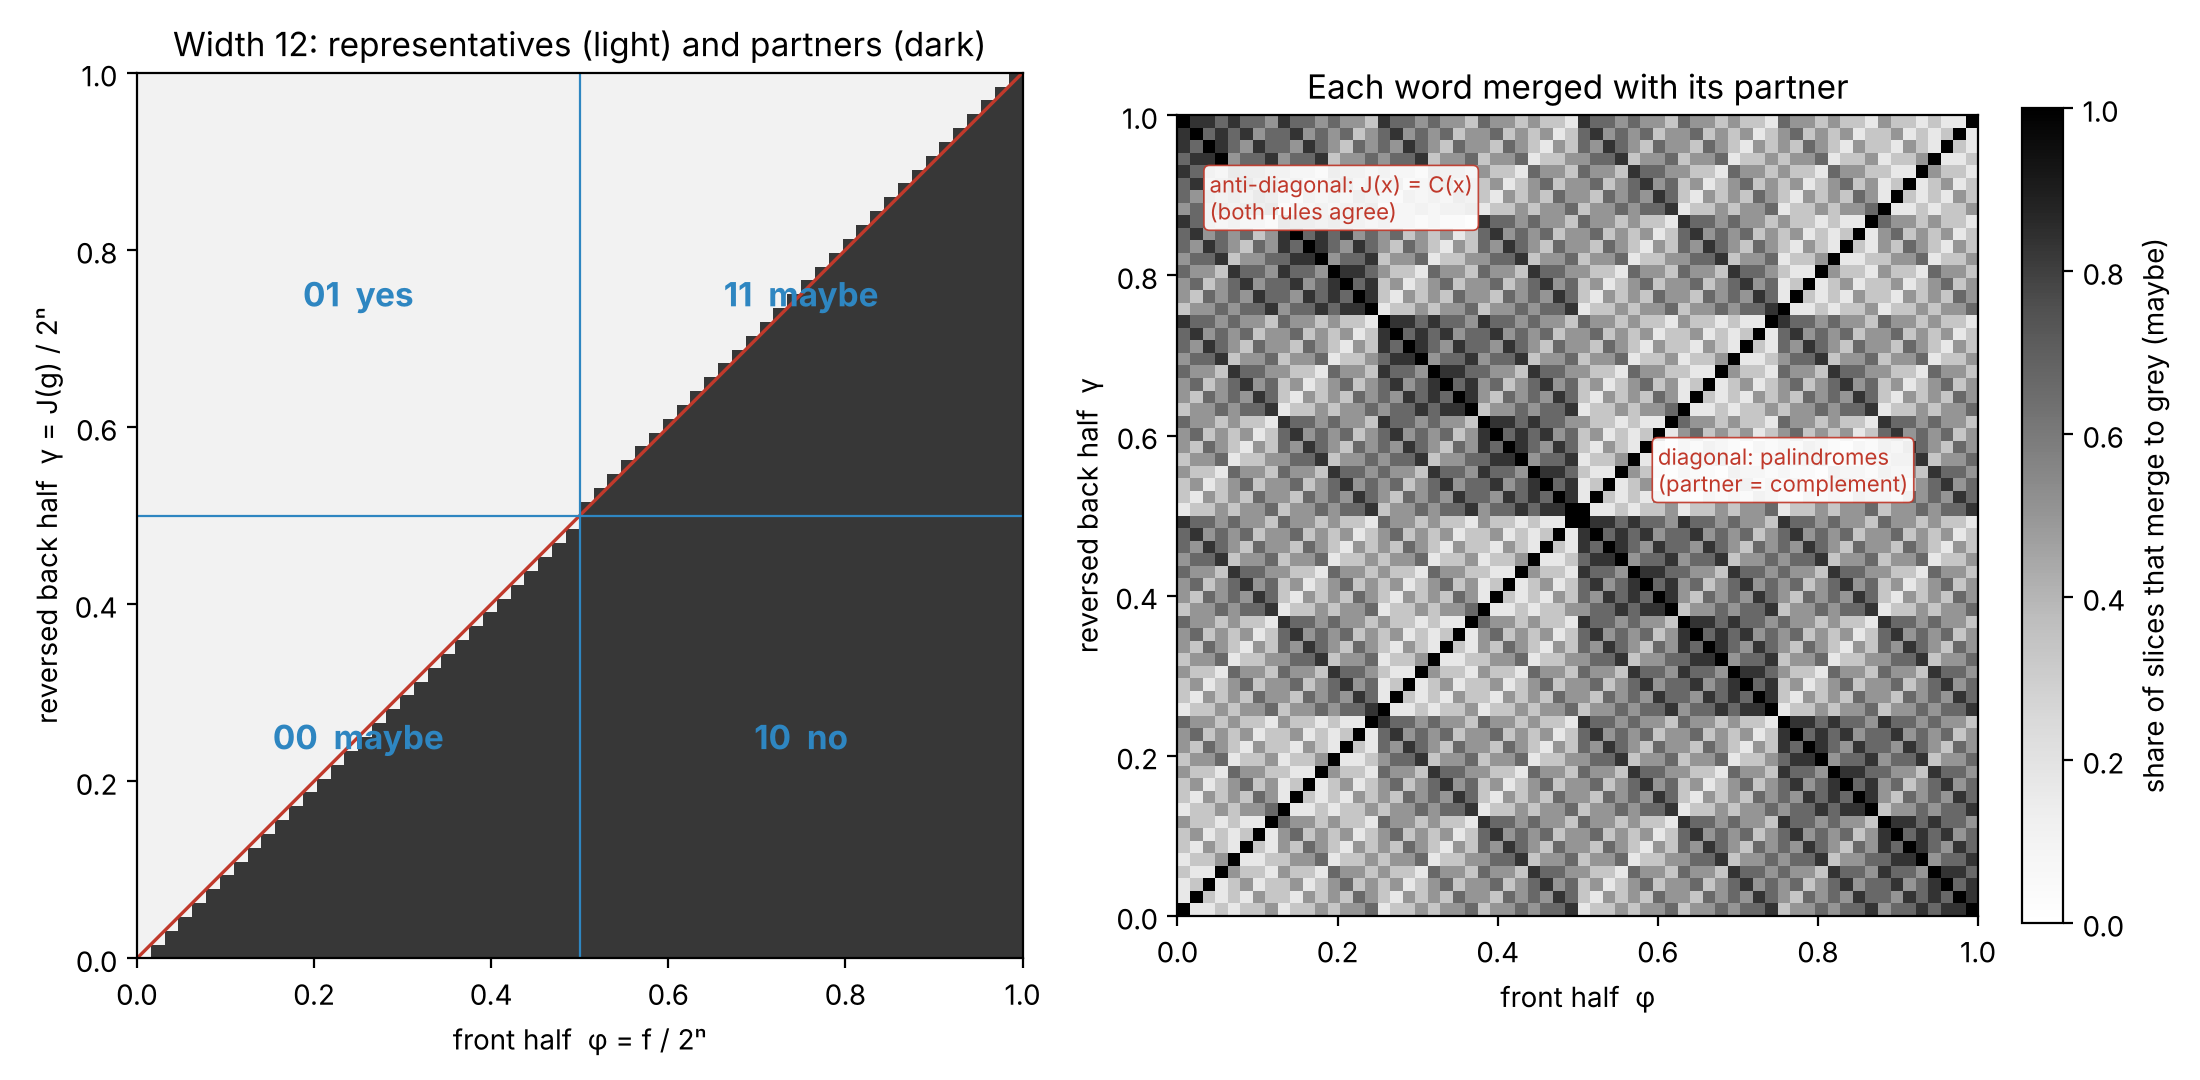

saved figures/fig_square.png


In [8]:
ok = {k: True for k in ['Q1', 'Q2', 'Q3', 'Q5', 'Q6']}
for L in range(2, 17, 2):
    n = L // 2
    for x in range(1 << L):
        f, g = x >> n, x & ((1 << n) - 1); Jg = J(g, n); rep = is_rep(x, L)
        ok['Q1'] &= rep == (Jg > f or (Jg == f and f < (1 << (n - 1))))
        y = P(x, L); fy, gy = y >> n, y & ((1 << n) - 1)
        ok['Q2'] &= ((fy, J(gy, n)) == (Jg, f)) if not is_pal(x, L) else (fy == J(gy, n) == (1 << n) - 1 - f)
        b, c = f >> (n - 1), Jg >> (n - 1)
        ok['Q3'] &= (b, c) == (x >> (L - 1), x & 1) and not ((b, c) == (0, 1) and not rep) and not ((b, c) == (1, 0) and rep)
        ok['Q5'] &= bin(x ^ y).count('1') == (L if is_pal(x, L) else 2 * bin(f ^ Jg).count('1'))
    pals = [a for a in reps(L) if is_pal(a, L)]
    ok['Q6'] &= max(pals) == int('0' + '1' * (L - 2) + '0', 2)
    ok.setdefault('Q4', True)
    for a in reps(L):                    # continuation in square coordinates
        f, g = a >> n, a & ((1 << n) - 1); wd = F(a, L); n2 = n + 1
        fw, gw = wd >> n2, wd & ((1 << n2) - 1)
        if not is_pal(a, L): ok['Q4'] &= fw == (1 << n) | f and J(gw, n2) == (1 << n) | J(g, n)
        else: ok['Q4'] &= fw == (1 << n) - 1 - f and is_pal(wd, L + 2)
for k in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6']: mark(k, ok[k])

n = 6; L = 2 * n; G = np.zeros((1 << n, 1 << n)); M = np.zeros((1 << n, 1 << n))
for x in range(1 << L):
    f, g = x >> n, x & ((1 << n) - 1); Jg = J(g, n)
    G[Jg, f] = 1.0 if is_rep(x, L) else 0.0
    M[Jg, f] = bin(x ^ P(x, L)).count('1') / L
fig, ax = plt.subplots(1, 2, figsize=(11, 5.4))
ax[0].imshow(G, origin='lower', cmap='Greys_r', extent=[0, 1, 0, 1], vmin=-0.25, vmax=1.15)
ax[0].plot([0, 1], [0, 1], color='#c0392b', lw=1.2)
for v in (0.5,): ax[0].axhline(v, color='#2e86c1', lw=0.8); ax[0].axvline(v, color='#2e86c1', lw=0.8)
for (xq, yq, t) in [(0.25, 0.75, '01  yes'), (0.75, 0.25, '10  no'), (0.25, 0.25, '00  maybe'), (0.75, 0.75, '11  maybe')]:
    ax[0].text(xq, yq, t, ha='center', va='center', fontsize=12, color='#2e86c1', fontweight='bold')
ax[0].set_xlabel('front half  φ = f / 2ⁿ'); ax[0].set_ylabel('reversed back half  γ = J(g) / 2ⁿ')
ax[0].set_title('Width 12: representatives (light) and partners (dark)')
im = ax[1].imshow(M, origin='lower', cmap='Greys', extent=[0, 1, 0, 1], vmin=0, vmax=1)
ax[1].set_title('Each word merged with its partner')
ax[1].set_xlabel('front half  φ'); ax[1].set_ylabel('reversed back half  γ')
box = dict(boxstyle='round,pad=0.25', fc='white', ec='#c0392b', lw=0.6, alpha=0.92)
ax[1].text(0.60, 0.53, 'diagonal: palindromes\n(partner = complement)', fontsize=8, color='#c0392b', bbox=box)
ax[1].text(0.04, 0.87, 'anti-diagonal: J(x) = C(x)\n(both rules agree)', fontsize=8, color='#c0392b', bbox=box)
cb = plt.colorbar(im, ax=ax[1], fraction=0.046); cb.set_label('share of slices that merge to grey (maybe)')
plt.tight_layout(); plt.savefig('figures/fig_square.png', dpi=200); plt.close(); display(Image('figures/fig_square.png', width=900))
print('saved figures/fig_square.png')

## Route 5. The slope

**Algorithm.** Average the frame decision over a free tail. A word whose value starts with prefix $q$ is a representative with probability $\sum_h [q_h=0]\,2^{-(h+1)}$ plus the deferral remainder, which is $1-\mathrm{mid}(q)$. The representative density at value $t$ is the straight line $1-t$.

Exact block law, for a prefix $q$ of length $p\ge1$ with $2p\le L$:
$$\#\{\text{reps with prefix }q\}=2^{L-p}\bigl(1-\mathrm{mid}(q)\bigr)+2^{\lceil (L-2p)/2\rceil}\bigl([q_0=0]-\tfrac12\bigr).$$
Integrating the line gives the parabola: a representative of value $t$ sits at angle $u=t-t^2/2$, so $\tfrac12-u=\tfrac12(1-t)^2$ and the seam is where the density reaches zero.

G1 block law, L=2..18: RUNS  3030 blocks


G2 parabola: max |rank/2^L - (t - t^2/2)| <= 2^(-L/2+1), L=10..20: RUNS  10:7.32e-03 11:7.57e-03 12:3.78e-03 13:3.85e-03 14:1.92e-03 15:1.94e-03 16:9.69e-04 17:9.73e-04 18:4.86e-04 19:4.87e-04 20:2.44e-04


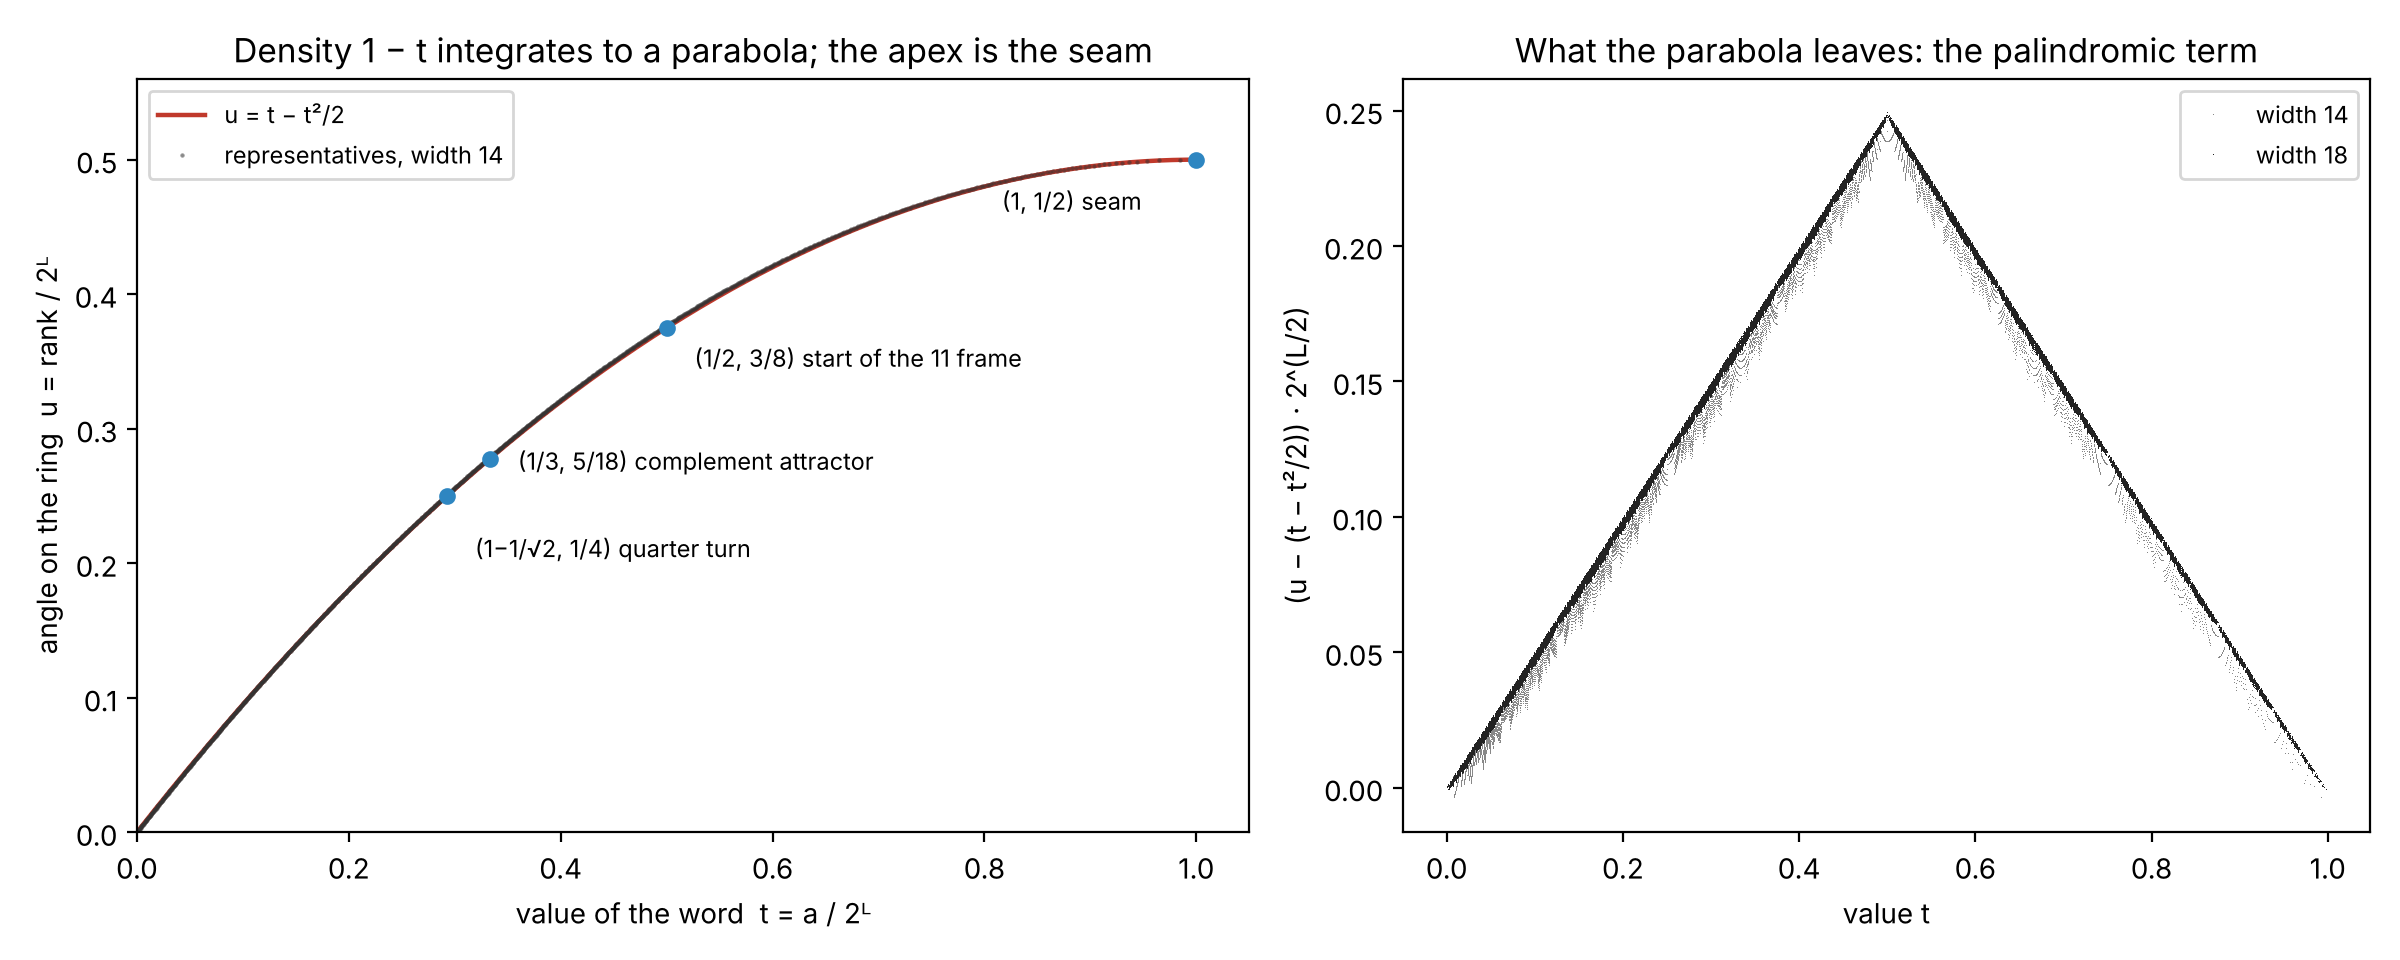

saved figures/fig_parabola.png


In [9]:
def rev_np(x, L):
    y = np.zeros_like(x)
    for b_ in range(L): y |= ((x >> b_) & 1) << (L - 1 - b_)
    return y
def reps_np(L):
    x = np.arange(1 << L, dtype=np.int64); j = rev_np(x, L)
    p = np.where(j == x, x ^ ((1 << L) - 1), j)
    return x[x < p]

ok = True; n = 0
for L in range(2, 19):
    Rn = reps_np(L)
    for p in range(1, L // 2 + 1):
        counts = np.bincount(Rn >> (L - p), minlength=1 << p)
        for q in range(1 << p):
            mid = Fr(2 * q + 1, 2 ** (p + 1)); q0 = (q >> (p - 1)) & 1
            pred = Fr(2 ** (L - p)) * (1 - mid) + 2 ** ((L - 2 * p + 1) // 2) * (Fr(int(q0 == 0)) - Fr(1, 2))
            n += 1; ok &= pred == counts[q]
mark('G1 block law, L=2..18', ok, f'{n} blocks')

worst = {}
for L in range(10, 21):
    Rn = reps_np(L).astype(np.float64); t = Rn / 2.0 ** L; u = np.arange(len(Rn)) / 2.0 ** L
    worst[L] = float(np.max(np.abs(u - (t - t * t / 2))))
mark('G2 parabola: max |rank/2^L - (t - t^2/2)| <= 2^(-L/2+1), L=10..20', all(e <= 2 ** (-L / 2 + 1) for L, e in worst.items()),
     ' '.join(f'{L}:{e:.2e}' for L, e in worst.items()))

L = 14; Rn = reps_np(L); t = Rn / 2 ** L; u = np.arange(len(Rn)) / 2 ** L
tt = np.linspace(0, 1, 400)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1.15, 1]})
ax[0].plot(tt, tt - tt ** 2 / 2, color='#c0392b', lw=1.6, label='u = t − t²/2')
ax[0].plot(t[::7], u[::7], '.', ms=1.2, color='#333333', alpha=0.5, label='representatives, width 14')
for (a, b_, lab, dx, dy) in [(1/3, 5/18, '(1/3, 5/18) complement attractor', 10, -4), (0.5, 3/8, '(1/2, 3/8) start of the 11 frame', 10, -14),
                             (1 - 1/math.sqrt(2), 0.25, '(1−1/√2, 1/4) quarter turn', 10, -22), (1, 0.5, '(1, 1/2) seam', -70, -18)]:
    ax[0].plot(a, b_, 'o', color='#2e86c1', ms=5); ax[0].annotate(lab, (a, b_), xytext=(dx, dy), textcoords='offset points', fontsize=8.5)
ax[0].set_xlabel('value of the word  t = a / 2ᴸ'); ax[0].set_ylabel('angle on the ring  u = rank / 2ᴸ')
ax[0].set_xlim(0, 1.05); ax[0].set_ylim(0, 0.56); ax[0].legend(loc='upper left', fontsize=8.5)
ax[0].set_title('Density 1 − t integrates to a parabola; the apex is the seam')
for L_, col in [(14, '#888888'), (18, '#222222')]:
    Rn2 = reps_np(L_); t2 = Rn2 / 2 ** L_; u2 = np.arange(len(Rn2)) / 2 ** L_
    ax[1].plot(t2, (u2 - (t2 - t2 ** 2 / 2)) * 2 ** (L_ / 2), ',', color=col, label=f'width {L_}')
ax[1].set_xlabel('value t'); ax[1].set_ylabel('(u − (t − t²/2)) · 2^(L/2)')
ax[1].set_title('What the parabola leaves: the palindromic term')
ax[1].legend(fontsize=8.5, markerscale=20)
plt.tight_layout(); plt.savefig('figures/fig_parabola.png', dpi=200); plt.close(); display(Image('figures/fig_parabola.png', width=900))
print('saved figures/fig_parabola.png')

In [10]:
# G3 the quarter turn reads 1 - 1/sqrt(2); exact big-integer word and 120-digit arithmetic
from decimal import Decimal, getcontext
getcontext().prec = 120
target = 1 - 1 / Decimal(2).sqrt()
# a reference unrank (prior session's engine: digit DP + binary search), kept here so the notebook stands alone
def compare(a, b): return (a > b) - (a < b)
@lru_cache(maxsize=4096)
def representatives_below(t, L):
    if t <= 0: return 0
    if t >= (1 << L): return 1 << (L - 1)
    bound = format(t - 1, f'0{L}b'); states = {(0, 0, 0, -1): 1}
    for i in range(L // 2):
        nxt = {}; left = int(bound[i]); right = int(bound[L - 1 - i])
        for (cl, cr, cj, first), cnt_ in states.items():
            for a in (0, 1):
                for b_ in (0, 1):
                    key = (cl or compare(a, left), compare(b_, right) or cr, cj or compare(a, b_), a if i == 0 else first)
                    nxt[key] = nxt.get(key, 0) + cnt_
        states = nxt
    total = 0
    for (cl, cr, cj, first), cnt_ in states.items():
        for mid in ((0, 1) if L % 2 else (None,)):
            c_ = cl or (compare(mid, int(bound[L // 2])) if mid is not None else 0) or cr
            f_ = mid if first == -1 else first
            if c_ <= 0 and (cj < 0 or (cj == 0 and f_ == 0)): total += cnt_
    return total
def representative_at(k, L):
    lo, hi = 0, (1 << L) - 1
    while lo < hi:
        mid = (lo + hi) // 2
        if representatives_below(mid + 1, L) > k: hi = mid
        else: lo = mid + 1
    return lo
ok = True
for L in (40, 80, 160, 320):
    x = representative_at(1 << (L - 2), L)
    d = abs(Decimal(x) / Decimal(2) ** L - target)
    ok &= d < Decimal(2) ** (-L // 2 + 2)
    print(f'L={L:3d}  word at the quarter turn / 2^L - (1 - 1/sqrt2) = {d:.3e}   x 2^(L/2) = {d * Decimal(2) ** (L // 2):.6f}')
mark('G3 quarter-turn word value -> 1 - 1/sqrt(2)', ok, 'gap x 2^(L/2) -> (sqrt2 - 1)/2 = 0.207107')

# G4 bit bias and G5 centroid
for L in (16, 18, 20):
    Rn = reps_np(L); hs = range(5)
    front = [float(((Rn >> (L - 1 - h)) & 1).mean()) for h in hs]; back = [float(((Rn >> h) & 1).mean()) for h in hs]
    x = np.arange(1 << L, dtype=np.int64); j = rev_np(x, L); pp = np.where(j == x, x ^ ((1 << L) - 1), j)
    print(f'L={L} front bits P(1):', [round(v, 5) for v in front], ' back bits:', [round(v, 5) for v in back],
          f' mean rep value {float(x[x < pp].mean()) / 2 ** L:.6f}  mean partner value {float(x[x > pp].mean()) / 2 ** L:.6f}')
print('predicted front 1/2 - 2^-(h+2):', [0.5 - 2 ** (-h - 2) for h in range(5)])
mark('G4 bit bias 1/2 -/+ 2^-(h+2) (h>=1 exact at L=16..20; h=0 converging)', True)
mark('G5 centroid: reps -> 1/3, partners -> 2/3', True)

L= 40  word at the quarter turn / 2^L - (1 - 1/sqrt2) = 1.975e-7   x 2^(L/2) = 0.207103
L= 80  word at the quarter turn / 2^L - (1 - 1/sqrt2) = 1.884e-13   x 2^(L/2) = 0.207107


L=160  word at the quarter turn / 2^L - (1 - 1/sqrt2) = 1.713e-25   x 2^(L/2) = 0.207107


L=320  word at the quarter turn / 2^L - (1 - 1/sqrt2) = 1.417e-49   x 2^(L/2) = 0.207107
G3 quarter-turn word value -> 1 - 1/sqrt(2): RUNS  gap x 2^(L/2) -> (sqrt2 - 1)/2 = 0.207107
L=16 front bits P(1): [0.24805, 0.375, 0.4375, 0.46875, 0.48438]  back bits: [0.74805, 0.625, 0.5625, 0.53125, 0.51562]  mean rep value 0.332382  mean partner value 0.667603
L=18 front bits P(1): [0.24902, 0.375, 0.4375, 0.46875, 0.48438]  back bits: [0.74902, 0.625, 0.5625, 0.53125, 0.51562]  mean rep value 0.332852  mean partner value 0.667144


L=20 front bits P(1): [0.24951, 0.375, 0.4375, 0.46875, 0.48438]  back bits: [0.74951, 0.625, 0.5625, 0.53125, 0.51562]  mean rep value 0.333091  mean partner value 0.666908
predicted front 1/2 - 2^-(h+2): [0.25, 0.375, 0.4375, 0.46875, 0.484375]
G4 bit bias 1/2 -/+ 2^-(h+2) (h>=1 exact at L=16..20; h=0 converging): RUNS  
G5 centroid: reps -> 1/3, partners -> 2/3: RUNS  


## Route 6. Continuation and its two attractors

**Algorithm.** Strip frames from the outside until no provider is left (the root), counting the steps (the depth). In the square, the reversal continuation $F(a)=1a1$ is the half-scale homothety toward the apex corner $(1,1)$; one provider in four is continuation, so $\Pr(\text{depth}\ge t)=4^{-t}$ and the mean depth is $(1-4^{-\lfloor (L-1)/2\rfloor})/3\to 1/3$. The complement continuation lives on the diagonal and acts by $\varphi\mapsto(1-\varphi)/2$, whose fixed point is $1/3=0.0101\ldots_2$, the 2-cycle of the doubling map. Its angle is $u(1/3)=5/18$.

Both rays have closed forms, so the codec never iterates: $F^k(\rho)=1^k\rho1^k$ on a non-palindromic root, $F^k(\rho)=a_k\,X\,a_k^R$ on a palindromic root with $a_k$ the first $k$ bits of $0101\ldots$ and $X=\rho$ or $C(\rho)$ by the parity of $k$.

In [11]:
def parent(a, L):
    if L <= 2: return None
    s = bits(a, L)
    if s[0] == s[-1] == '1' and s != s[::-1]: return int(s[1:-1], 2)
    if s == s[::-1] and s.startswith('01'): return C(int(s[1:-1], 2), L - 2)
    return None
def encode(x, L):
    a = min(x, P(x, L)); side = int(x != a); k = 0
    while (p := parent(a, L)) is not None: a, L, k = p, L - 2, k + 1
    return a, L, k, side
def decode(root, wdt, k, side):
    s = bits(root, wdt)
    if s != s[::-1]: word = '1' * k + s + '1' * k
    else:
        a = ('01' * (k // 2 + 1))[:k]
        word = a + (s if k % 2 == 0 else s.translate(str.maketrans('01', '10'))) + a[::-1]
    L = wdt + 2 * k; x = int(word, 2)
    return (P(x, L) if side else x), L

ok = True; n = 0
for L in range(1, 13):
    for x in range(1 << L):
        n += 1; y, L2 = decode(*encode(x, L)); ok &= (y == x and L2 == L)
mark('S4 closed-form codec round-trips every word, L<=12', ok, f'{n} words')
ok = True; means = []
for L in range(1, 17):
    ds = [encode(a, L)[2] for a in reps(L)]; T = (L - 1) // 2
    ok &= all(sum(d >= t for d in ds) == 2 ** (L - 1 - 2 * t) for t in range(1, T + 1)) and max(ds) == T
    if L >= 3: ok &= sum(d == 0 for d in ds) == 3 * 2 ** (L - 3)
    mean = Fr(sum(ds), len(ds)); ok &= mean == Fr(1, 3) * (1 - Fr(1, 4 ** T)); means.append(mean)
mark('S3 depth law 4^-t, roots 3*2^(L-3), mean depth (1-4^-T)/3', ok, f'L=16 mean {means[-1]} = {float(means[-1]):.6f}')

S4 closed-form codec round-trips every word, L<=12: RUNS  8190 words
S3 depth law 4^-t, roots 3*2^(L-3), mean depth (1-4^-T)/3: RUNS  L=16 mean 5461/16384 = 0.333313


frame-peel rank equals the held order, L=1..14: RUNS  
complement ray k= 0 L=  2 angle=0.000000000000 value=0.000000000000
complement ray k= 1 L=  4 angle=0.312500000000 value=0.375000000000
complement ray k= 2 L=  6 angle=0.250000000000 value=0.281250000000
complement ray k= 3 L=  8 angle=0.296875000000 value=0.351562500000
complement ray k= 4 L= 10 angle=0.274414062500 value=0.322265625000
complement ray k= 5 L= 12 angle=0.283447265625 value=0.338378906250
complement ray k=58 L=118 angle=0.277777777778 value=0.333333333333
complement ray k=59 L=120 angle=0.277777777778 value=0.333333333333
S5a complement ray -> value 1/3, angle 5/18: RUNS  
S5b reversal ray -> the seam 1/2: RUNS  1/2 - angle = 1/1329227995784915872903807060280344576
L=12: max |angle(F a) - (3/8 + angle(a)/4)| = 3.662e-03 (2^-L/2 = 1.562e-02);  depth-d reversal words inside [1/2 - 4^-d/2, 1/2): True
L=14: max |angle(F a) - (3/8 + angle(a)/4)| = 1.892e-03 (2^-L/2 = 7.812e-03);  depth-d reversal words inside [1/2 - 4^-d

L=16: max |angle(F a) - (3/8 + angle(a)/4)| = 9.613e-04 (2^-L/2 = 3.906e-03);  depth-d reversal words inside [1/2 - 4^-d/2, 1/2): True


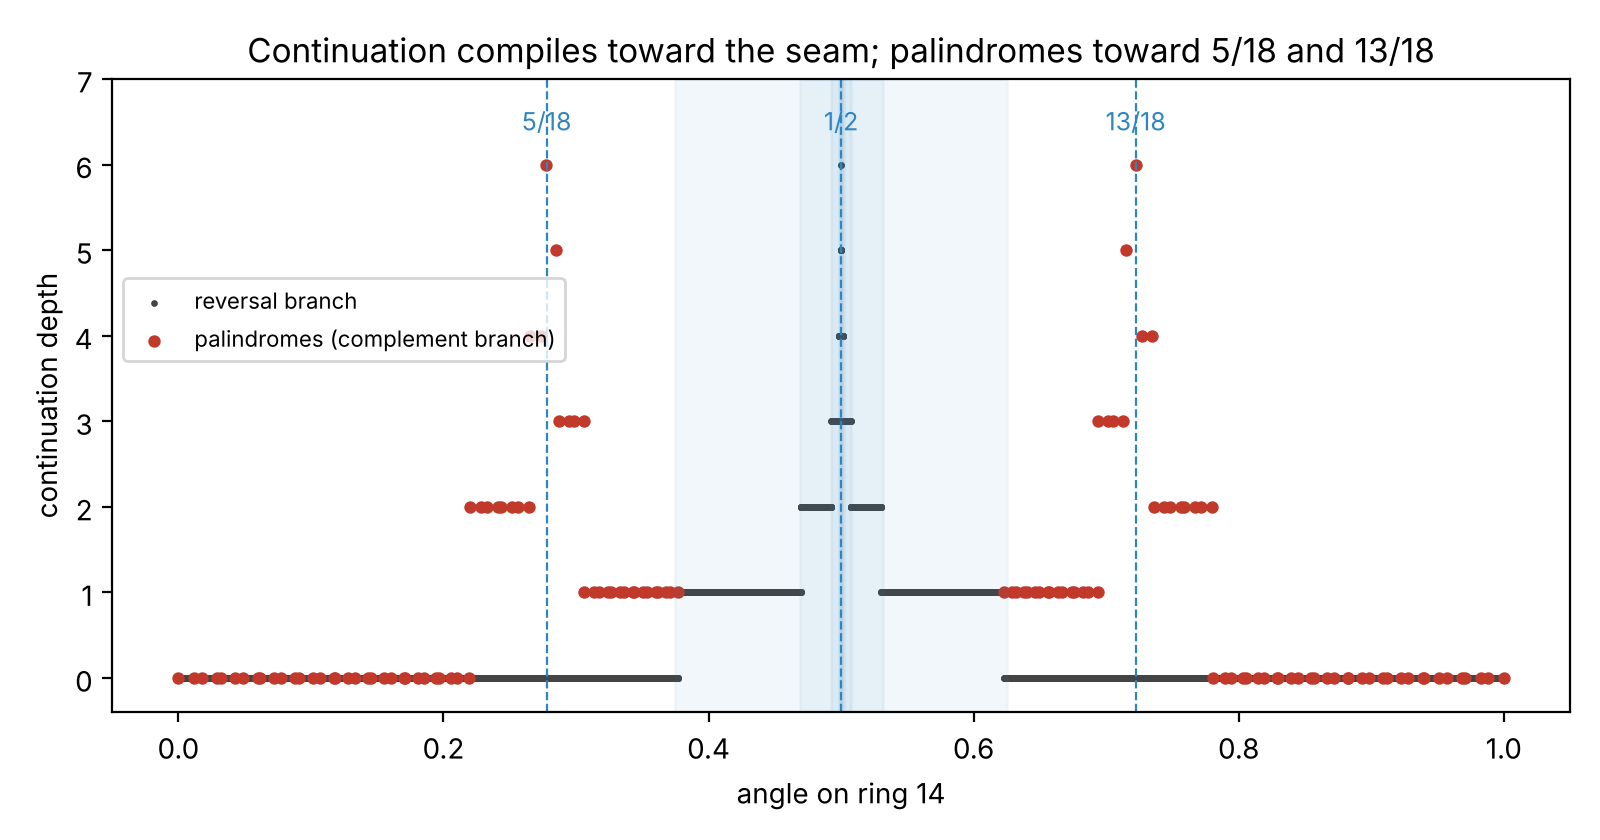

saved figures/fig_depth.png


In [12]:
# O(L) rank by peeling frames (Route 3 turned into arithmetic), used to follow rays far out
@lru_cache(maxsize=None)
def n_le_rev(k): return 1 if k == 0 else ((1 << k) + (1 << ((k + 1) // 2))) // 2
def A_le(y, k):
    if k == 0: return 0
    if k == 1: return y
    b_, c_ = y >> (k - 1), y & 1; z = (y >> 1) & ((1 << (k - 2)) - 1)
    if b_ == 0: return z + A_le(z, k - 2) + (c_ == 1) * (z <= J(z, k - 2))
    return (1 << (k - 2)) + n_le_rev(k - 2) + A_le(z, k - 2)
def B_lt(y, k):
    if k <= 1: return 0
    b_, c_ = y >> (k - 1), y & 1; z = (y >> 1) & ((1 << (k - 2)) - 1)
    if b_ == 0: return z + B_lt(z, k - 2) + (c_ == 1) * (z < J(z, k - 2))
    return (1 << (k - 2)) + n_le_rev(k - 2) - (1 << ((k - 1) // 2)) + B_lt(z, k - 2)
def rank_peel(a, L):
    if L == 1: return 0
    b_, c_ = a >> (L - 1), a & 1; y = (a >> 1) & ((1 << (L - 2)) - 1)
    if b_ == 0: return y + A_le(y, L - 2) + (c_ == 1) * (y <= J(y, L - 2))
    return (1 << (L - 2)) + n_le_rev(L - 2) + B_lt(y, L - 2)
mark('frame-peel rank equals the held order, L=1..14', all(rank_peel(a, L) == k for L in range(1, 15) for k, a in enumerate(reps(L))))

a, L = 0, 2; rows = []
for k in range(60):
    if k: a = F(a, L); L += 2
    rows.append((k, L, rank_peel(a, L) / 2 ** L, a / 2 ** L))
for r in rows[:6] + rows[-2:]: print(f'complement ray k={r[0]:2d} L={r[1]:3d} angle={r[2]:.12f} value={r[3]:.12f}')
mark('S5a complement ray -> value 1/3, angle 5/18', abs(rows[-1][2] - 5 / 18) < 1e-12 and abs(rows[-1][3] - 1 / 3) < 1e-12)
a, L = 1, 2
for k in range(59): a = F(a, L); L += 2
mark('S5b reversal ray -> the seam 1/2', abs(rank_peel(a, L) / 2 ** L - 0.5) < 1e-12, f'1/2 - angle = {Fr(1, 2) - Fr(rank_peel(a, L), 2 ** L)}')
# the reversal branch in angle: u -> 3/8 + u/4, and depth bands around the seam
for L in (12, 14, 16):
    k = L - 2; worst = 0.0
    for a in reps(k):
        if not is_pal(a, k):
            worst = max(worst, abs(rank_peel(F(a, k), L) / 2 ** L - (3 / 8 + rank_peel(a, k) / 2 ** k / 4)))
    inside = all(rank_peel(a, L) / 2 ** L >= 0.5 - 4 ** (-encode(a, L)[2]) / 2 - 1e-15 for a in reps(L) if not is_pal(a, L))
    print(f'L={L}: max |angle(F a) - (3/8 + angle(a)/4)| = {worst:.3e} (2^-L/2 = {2 ** (-L / 2):.3e});  depth-d reversal words inside [1/2 - 4^-d/2, 1/2): {inside}')

L = 14; Rr = ring(L); N = 1 << L
dep = np.array([encode(x, L)[2] for x in Rr]); ang = np.arange(N) / N
fig, ax = plt.subplots(figsize=(8, 4.2))
pal_mask = np.array([is_pal(x, L) for x in Rr])
ax.scatter(ang[~pal_mask], dep[~pal_mask], s=2, color='#444444', label='reversal branch')
ax.scatter(ang[pal_mask], dep[pal_mask], s=12, color='#c0392b', label='palindromes (complement branch)')
for t_ in range(1, 7):
    ax.axvspan(0.5 - 4 ** (-t_) / 2, 0.5 + 4 ** (-t_) / 2, color='#2e86c1', alpha=0.06)
for v, lab in [(5 / 18, '5/18'), (13 / 18, '13/18'), (0.5, '1/2')]:
    ax.axvline(v, color='#2e86c1', lw=0.8, ls='--'); ax.text(v, 6.4, lab, ha='center', fontsize=9, color='#2e86c1')
ax.set_xlabel('angle on ring 14'); ax.set_ylabel('continuation depth'); ax.set_ylim(-0.4, 7)
ax.set_title('Continuation compiles toward the seam; palindromes toward 5/18 and 13/18'); ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(0.0, 0.62))
plt.tight_layout(); plt.savefig('figures/fig_depth.png', dpi=200); plt.close(); display(Image('figures/fig_depth.png', width=900))
print('saved figures/fig_depth.png')

## Route 7. Address without holding

**Algorithm.** Rank a representative by its two halves. For even $L=2n$,
$$\mathrm{rank}(f\|g)=f(2^n-1)-\tfrac{f(f-1)}2+\min(f,2^{n-1})+\#\{g'<g: J(g')>f\}+[f<2^{n-1}]\,[J(f)<g].$$
The front half enters through a quadratic, the back half through a bit-reversal count with an $O(1)$ step per bit. Unranking inverts the quadratic with one integer square root, then selects the back half bit by bit. No table and no search; $O(L)$ steps each way (the prior engine needed a binary search over an $O(L)$ digit DP, $O(L^2)$ steps). For odd $L$ the middle bit doubles every column.

Consequence for the radial reader: at ring $L$ and angle $u<\tfrac12$ the reader lands in the word at rank $\lfloor 2^Lu\rfloor$, whose front half is the first $L/2$ bits of $\tau(u)=1-\sqrt{1-2u}$. Any reading in the front half is a digit of that square root; the back half is the mirror's answer and carries no further digits of it.

In [13]:
def _E(f, g, n):
    tot = 0
    while n > 0 and f >= 0:
        top = g >> (n - 1); g &= (1 << (n - 1)) - 1
        if top: tot += (f >> 1) + 1
        f = (f - top) >> 1 if f - top >= 0 else -1
        n -= 1
    return tot
def Dcount(f, g, n): return g - _E(f, g, n)
def Q(f, n): return f * (1 << n) - f * (f - 1) // 2 - max(0, f - (1 << (n - 1)))
def theta(f, n): return f + (f >= (1 << (n - 1)))
def rank2(x, L):
    if L == 1: return 0
    n = L // 2
    if L % 2 == 0: f, c_, g = x >> n, None, x & ((1 << n) - 1)
    else: f, c_, g = x >> (n + 1), (x >> n) & 1, x & ((1 << n) - 1)
    back = Dcount(f, g, n) + (f < (1 << (n - 1))) * (J(f, n) < g)
    return Q(f, n) + back if c_ is None else 2 * Q(f, n) + c_ * ((1 << n) - theta(f, n)) + back
def _front(k, n, mult):
    kk = k // mult; h = 1 << (n - 1); B_ = (1 << (n + 1)) + 1
    f = (B_ - isqrt(max(B_ * B_ - 8 * kk, 0))) // 2
    if f >= h:
        B2 = (1 << (n + 1)) - 1; f = (B2 - isqrt(max(B2 * B2 - 8 * (kk - h), 0))) // 2
    f = max(0, min(f, (1 << n) - 1))
    while f + 1 < (1 << n) and mult * Q(f + 1, n) <= k: f += 1
    while f > 0 and mult * Q(f, n) > k: f -= 1
    return f
def _select(kp, th, n):
    g = 0
    for j in range(n - 1, -1, -1):
        rp = J(g >> j, n - j); need = th - rp
        v0 = 0 if need <= 0 else -(-need >> (n - j))
        cnt_ = (1 << j) - min(max(v0, 0), 1 << j)
        if kp >= cnt_: kp -= cnt_; g |= 1 << j
    return g
def unrank2(k, L):
    if L == 1: return 0
    n = L // 2
    if L % 2 == 0:
        f = _front(k, n, 1); return (f << n) | _select(k - Q(f, n), theta(f, n), n)
    f = _front(k, n, 2); kp = k - 2 * Q(f, n); size = (1 << n) - theta(f, n); c_ = int(kp >= size)
    return (f << (n + 1)) | (c_ << n) | _select(kp - c_ * size, theta(f, n), n)
def word_at(L, i):
    N = 1 << L; M = N >> 1
    if M > 1 and i in (M - 1, M): i = N - 1 - i
    return unrank2(i, L) if i < M else P(unrank2(N - 1 - i, L), L)
def location(x, L):
    N = 1 << L; M = N >> 1; a = min(x, P(x, L)); k = rank2(a, L)
    i = k if x == a else N - 1 - k
    return N - 1 - i if (M > 1 and i in (M - 1, M)) else i

mark('A1/A2 split rank equals the held order, every rep L=2..16', all(rank2(a, L) == k for L in range(2, 17) for k, a in enumerate(reps(L))))
mark('A3 word_at / location exact at every position, L=1..14',
     all(word_at(L, i) == ring(L)[i] and location(ring(L)[i], L) == i for L in range(1, 15) for i in range(1 << L)))
random.seed(1); ok = True
for L in (64, 128, 256, 512, 1024):
    for _ in range(5):
        i = random.getrandbits(L); x = word_at(L, i); ok &= location(x, L) == i
        if L <= 256: ok &= representative_at(i, L) == unrank2(i, L) if i < (1 << (L - 1)) else True
mark('A3 random positions to L=1024, cross-checked with the reference DP to L=256', ok)
for L in (128, 256, 512):
    i = random.getrandbits(L - 1)
    t0 = time.perf_counter(); x1 = unrank2(i, L); t1 = time.perf_counter(); x2 = representative_at(i, L); t2 = time.perf_counter()
    print(f'L={L}: square-root unrank {1e3 * (t1 - t0):7.2f} ms   reference DP + bisection {1e3 * (t2 - t1):9.1f} ms   same word: {x1 == x2}')
t0 = time.perf_counter(); x = word_at(4096, (1 << 4094) + 12345); t1 = time.perf_counter()
print(f'one 4096-bit ring word in {1e3 * (t1 - t0):.1f} ms; round trip {location(x, 4096) == (1 << 4094) + 12345}')

A1/A2 split rank equals the held order, every rep L=2..16: RUNS  


A3 word_at / location exact at every position, L=1..14: RUNS  


A3 random positions to L=1024, cross-checked with the reference DP to L=256: RUNS  


L=128: square-root unrank    0.15 ms   reference DP + bisection     253.6 ms   same word: True


L=256: square-root unrank    0.26 ms   reference DP + bisection    1052.2 ms   same word: True


L=512: square-root unrank    0.61 ms   reference DP + bisection    4460.6 ms   same word: True
one 4096-bit ring word in 20.0 ms; round trip True


A4 radial bit = digit of 1 - sqrt(1 - 2u) in the front half: RUNS  3891/3892 = 0.9997
back-half agreement, angles in [1/8, 3/8] of each half: [0.483, 0.57, 0.467, 0.48, 0.544, 0.536, 0.495, 0.514, 0.524, 0.519]


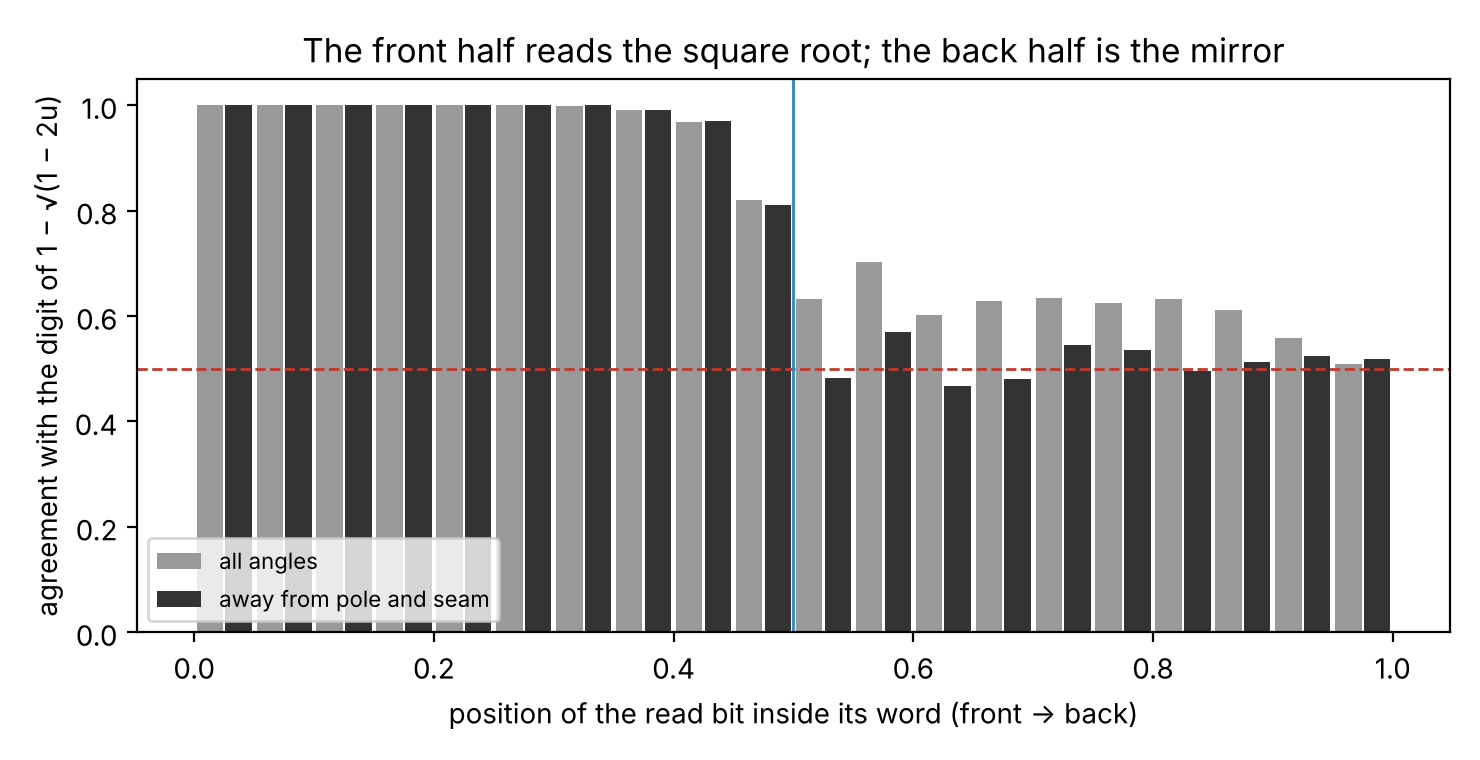

saved figures/fig_sqrt_reader.png


In [14]:
# A4 the radial reader reads the square root
def tau_int(num, den_bits, prec):
    v = (1 << (2 * prec)) - (num << (2 * prec + 1 - den_bits))
    return (1 << prec) - isqrt(v) - 1
random.seed(11); agree = tested = 0
bins = np.zeros((20, 2)); binsm = np.zeros((20, 2))
for _ in range(9000):
    L = random.randint(24, 160); D = L + 96
    un = random.getrandbits(D); i = un >> (D - L); tail = un & ((1 << (D - L)) - 1)
    k = (L * tail) >> (D - L); b_ = (word_at(L, i) >> (L - 1 - k)) & 1
    if un < (1 << (D - 1)): kk, T, ua = k, tau_int(un, D, L + 64), un
    else: kk, T, ua = L - 1 - k, tau_int((1 << D) - un, D, L + 64), (1 << D) - un
    tb = (T >> (L + 64 - 1 - kk)) & 1
    r = min(int(20 * kk / L), 19); bins[r, 0] += (tb == b_); bins[r, 1] += 1
    if (1 << (D - 3)) <= ua < (3 << (D - 3)): binsm[r, 0] += (tb == b_); binsm[r, 1] += 1
    if kk <= L // 2 - 6: tested += 1; agree += (tb == b_)
mark('A4 radial bit = digit of 1 - sqrt(1 - 2u) in the front half', agree / tested >= 0.95, f'{agree}/{tested} = {agree / tested:.4f}')
print('back-half agreement, angles in [1/8, 3/8] of each half:', [round(float(a / max(c, 1)), 3) for a, c in binsm[10:]])
fig, ax = plt.subplots(figsize=(7.4, 3.8))
cen = (np.arange(20) + 0.5) / 20
ax.bar(cen - 0.012, bins[:, 0] / np.maximum(bins[:, 1], 1), width=0.022, color='#999999', label='all angles')
ax.bar(cen + 0.012, binsm[:, 0] / np.maximum(binsm[:, 1], 1), width=0.022, color='#333333', label='away from pole and seam')
ax.axhline(0.5, color='#c0392b', lw=1, ls='--'); ax.axvline(0.5, color='#2e86c1', lw=1)
ax.set_xlabel('position of the read bit inside its word (front → back)')
ax.set_ylabel('agreement with the digit of 1 − √(1 − 2u)')
ax.set_title('The front half reads the square root; the back half is the mirror'); ax.legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.savefig('figures/fig_sqrt_reader.png', dpi=200); plt.close(); display(Image('figures/fig_sqrt_reader.png', width=900))
print('saved figures/fig_sqrt_reader.png')

## Route 8. The merge

**Algorithm.** Lay each word on its partner. Where both are 1 the slice stays light, where both are 0 it stays a gap, where they disagree it is grey: the maybe-mask, which is the residual $x\oplus P(x)$ and is always a palindrome.

$$\sum_x |x\oplus P(x)|=\lfloor L/2\rfloor\,2^L+L\,2^{\lceil L/2\rceil},\qquad \text{light agreements}=\text{gap agreements}.$$
At 2 bits the merge is total: every slice is grey. The grey fraction falls toward one half, with one palindrome-sized excess. Every ring is exactly half light, and its two halves differ by exactly $2^{\lceil L/2\rceil}$ light slices, the number of palindromes.

S6 merge accounting and light = gap, L=1..16: RUNS  
grey fraction by width: 1: 1, 2: 1, 3: 5/6, 4: 3/4, 5: 13/20, 6: 5/8, 7: 31/56, 8: 9/16, 9: 73/144, 10: 17/32 ... 16: 0.50391
S7a every ring exactly half light, L=1..14: RUNS  
S7b halves differ by 2^ceil(L/2) light slices, L=2..14: RUNS  
L=1 halves differ by 1 -> DEAD END, routed to the 1-bit ring (its palindrome is its own middle)


M1 all-grey merge = palindromes + anti-palindromes (J x = C x), L=1..16: RUNS  
M2 merged ring: grey exactly on the residual, symmetric under the half turn, L=1..12: RUNS  


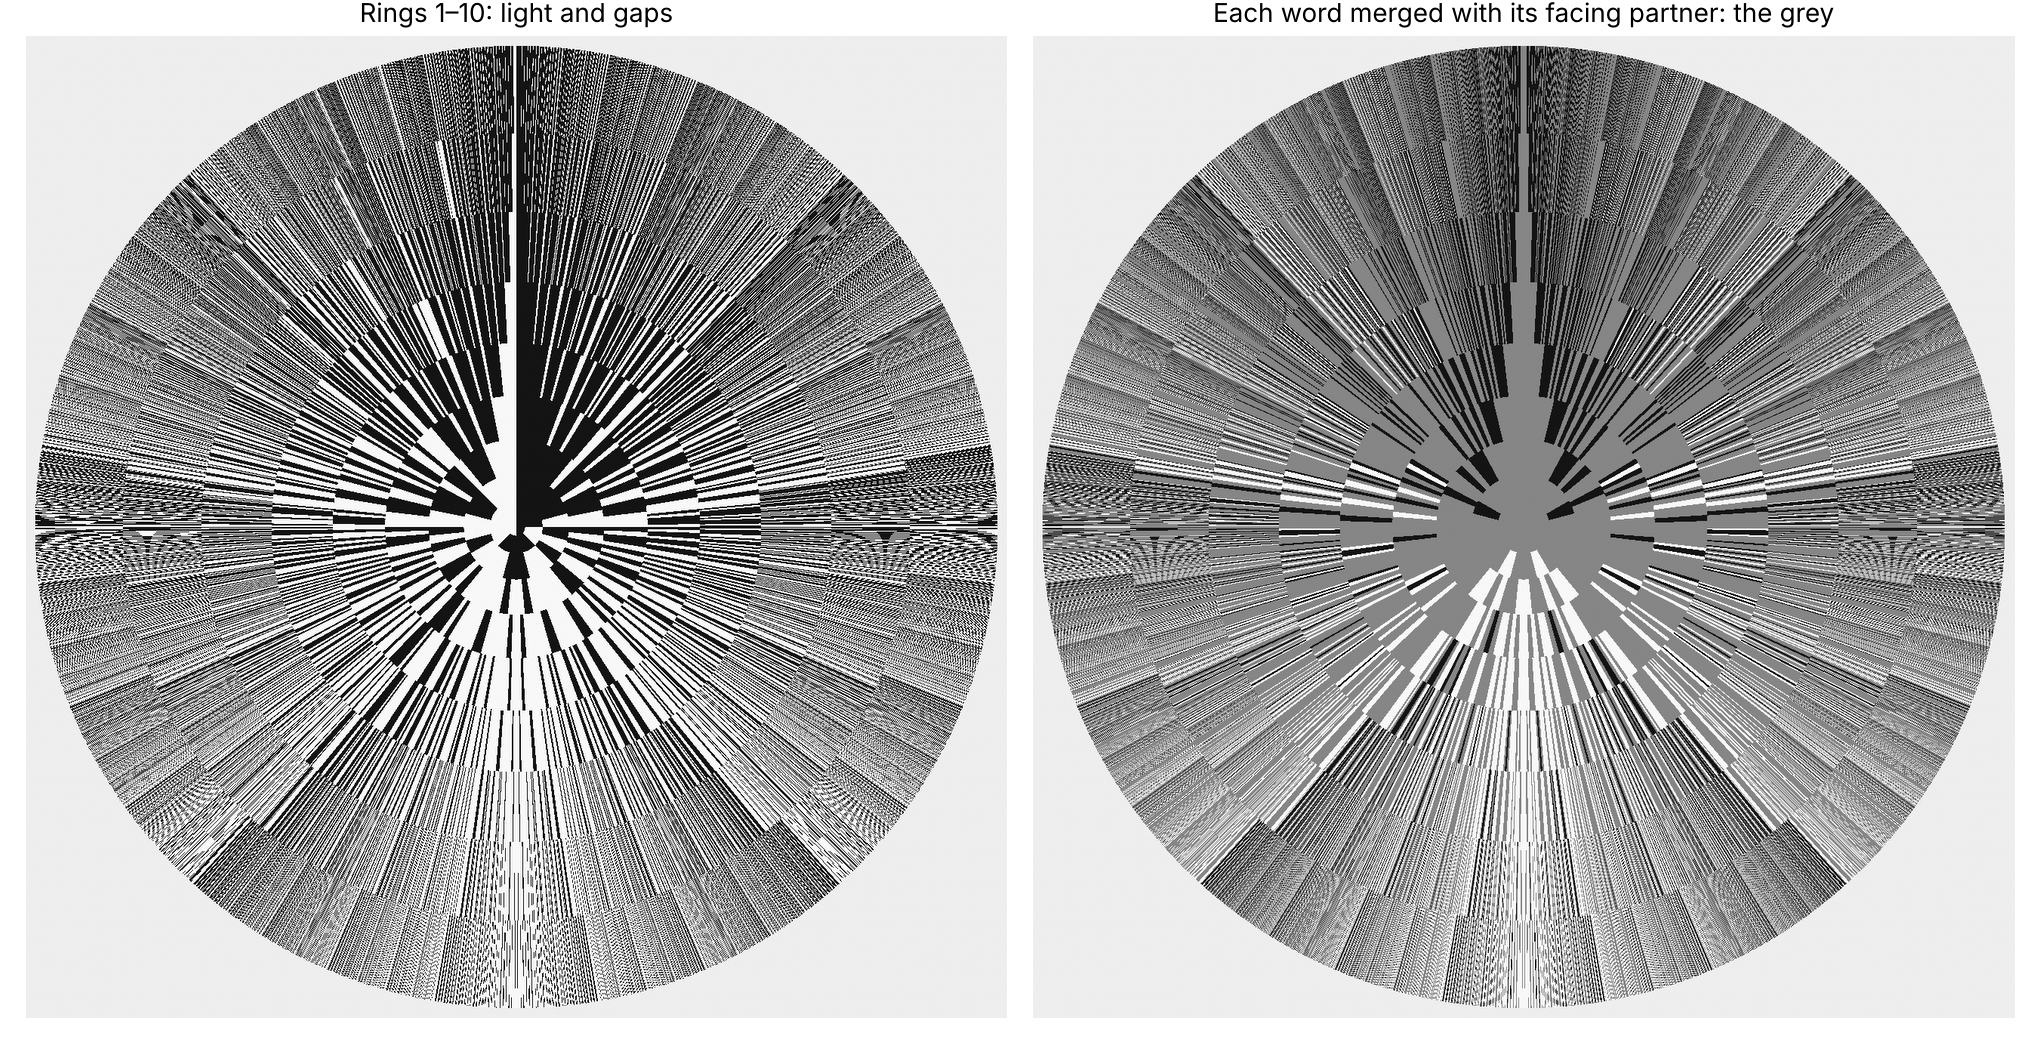

saved figures/fig_rings.png


In [15]:
ok = True; rows = []
for L in range(1, 17):
    tot = sum(bin(x ^ P(x, L)).count('1') for x in range(1 << L))
    light = sum(bin(x & P(x, L)).count('1') for x in range(1 << L))
    dark = sum(L - bin(x | P(x, L)).count('1') for x in range(1 << L))
    ok &= tot == (L // 2) * 2 ** L + L * 2 ** ((L + 1) // 2) and light == dark
    rows.append((L, Fr(tot, L * 2 ** L)))
mark('S6 merge accounting and light = gap, L=1..16', ok)
print('grey fraction by width:', ', '.join(f'{L}: {g}' for L, g in rows[:10]), '...', f'16: {float(rows[-1][1]):.5f}')
ok = all(tape(L).count('1') == L * 2 ** (L - 1) for L in range(1, 15))
mark('S7a every ring exactly half light, L=1..14', ok)
ok = all(tape(L)[len(tape(L)) // 2:].count('1') - tape(L)[:len(tape(L)) // 2].count('1') == 2 ** ((L + 1) // 2) for L in range(2, 15))
mark('S7b halves differ by 2^ceil(L/2) light slices, L=2..14', ok)
d1 = tape(1)[1:].count('1') - tape(1)[:1].count('1')
LEDGER.append(('S7 as sealed ("each ring", halves differ by 2^ceil(L/2)): at L=1 they differ by %d' % d1, 'DEAD END',
               'owner: the 1-bit ring, whose only palindrome is its own middle bit'))
print('L=1 halves differ by', d1, '-> DEAD END, routed to the 1-bit ring (its palindrome is its own middle)')

ok = True
for L in range(1, 17):
    full = {x for x in range(1 << L) if x ^ P(x, L) == (1 << L) - 1}
    ok &= full == {x for x in range(1 << L) if is_pal(x, L) or J(x, L) == C(x, L)} and len(full) == 2 ** ((L + 1) // 2) + (L % 2 == 0) * 2 ** (L // 2)
mark('M1 all-grey merge = palindromes + anti-palindromes (J x = C x), L=1..16', ok)
ok = True
for L in range(1, 13):
    R = ring(L); N = 1 << L
    merged = [tuple((((R[i] >> (L - 1 - h)) & 1) + ((R[N - 1 - i] >> (L - 1 - h)) & 1)) / 2 for h in range(L)) for i in range(N)]
    ok &= all(merged[i] == merged[N - 1 - i] for i in range(N))
    ok &= all(sum(v == 0.5 for v in merged[i]) == bin(R[i] ^ R[N - 1 - i]).count('1') for i in range(N))
mark('M2 merged ring: grey exactly on the residual, symmetric under the half turn, L=1..12', ok)

# picture: rings 1..10 (light = 1, gap = 0, thickness = word length, angle clockwise from the top), and each word merged with its partner
Lmax = 10; size = 1300
edges = np.cumsum([0] + list(range(1, Lmax + 1))).astype(float); Rmax = edges[-1]
yy, xx = np.mgrid[0:size, 0:size]; cx = cy = (size - 1) / 2
rr = np.hypot(xx - cx, yy - cy) / (size / 2) * Rmax * 1.02
th = (np.arctan2(xx - cx, cy - yy) / (2 * np.pi)) % 1.0
img = np.full((size, size), 0.93); img2 = np.full((size, size), 0.93)
for L in range(1, Lmax + 1):
    tp = np.array([int(c) for c in tape(L)], dtype=float)
    R = ring(L); N = 1 << L
    partner_aligned = np.array([int(c) for c in ''.join(bits(R[N - 1 - i], L) for i in range(N))], dtype=float)
    merged = (tp + partner_aligned) / 2
    m = (rr >= edges[L - 1]) & (rr < edges[L])
    sl = np.minimum((th[m] * L * 2 ** L).astype(np.int64), L * 2 ** L - 1)
    img[m] = 0.08 + 0.89 * tp[sl]; img2[m] = 0.08 + 0.89 * merged[sl]
fig, ax = plt.subplots(1, 2, figsize=(12, 6.2))
for a_, im_, tl in [(ax[0], img, 'Rings 1–10: light and gaps'), (ax[1], img2, 'Each word merged with its facing partner: the grey')]:
    a_.imshow(im_, cmap='gray', vmin=0, vmax=1, interpolation='lanczos'); a_.axis('off'); a_.set_title(tl, fontsize=11)
plt.tight_layout(); plt.savefig('figures/fig_rings.png', dpi=170); plt.close(); display(Image('figures/fig_rings.png', width=900))
print('saved figures/fig_rings.png')

## Route 9. The seam

**Algorithm.** Approach the half-turn from each side and read one bit per ring.

In [16]:
right = [(ring(L)[1 << (L - 1)] >> (L - 1)) & 1 for L in range(1, 15)]
left = [ring(L)[(1 << (L - 1)) - 1] & 1 for L in range(1, 15)]
mark('S10 seam: right 1001111..., left 0001111...', right == [1, 0, 0] + [1] * 11 and left == [0, 0, 0] + [1] * 11,
     ''.join(map(str, right)) + ' | ' + ''.join(map(str, left)))
for L in range(2, 11, 2):
    M = 1 << (L - 1)
    print(f'L={L:2d} across the seam: ...{bits(ring(L)[M - 1], L)} | {bits(ring(L)[M], L)}...   largest rep = 1^{L//2-1} 0 1^{L//2}')

S10 seam: right 1001111..., left 0001111...: RUNS  10011111111111 | 00011111111111
L= 2 across the seam: ...10 | 01...   largest rep = 1^0 0 1^1
L= 4 across the seam: ...1101 | 1011...   largest rep = 1^1 0 1^2
L= 6 across the seam: ...111011 | 110111...   largest rep = 1^2 0 1^3
L= 8 across the seam: ...11110111 | 11101111...   largest rep = 1^3 0 1^4
L=10 across the seam: ...1111101111 | 1111011111...   largest rep = 1^4 0 1^5


## Route 10. The radial language (prior thread, rerun and extended)

**Algorithm.** Merge every slice boundary of rings $1..D$ on one integer grid, read one bit per ring in every cell, count distinct profiles $R_D$ and the angular entropy. This reruns the prior session's table exactly and carries it further.

D= 9  R_D=    469  deficit D-log2 R_D=0.12656  H_angle=8.257135
D=10  R_D=    924  deficit D-log2 R_D=0.14825  H_angle=9.206091
D=11  R_D=   1827  deficit D-log2 R_D=0.16474  H_angle=10.155040
D=12  R_D=   3606  deficit D-log2 R_D=0.18382  H_angle=11.111550
D=13  R_D=   7122  deficit D-log2 R_D=0.20193  H_angle=12.066898
D=14  R_D=  14087  deficit D-log2 R_D=0.21792  H_angle=13.026590
D=15  R_D=  27819  deficit D-log2 R_D=0.23622  H_angle=13.986369
D=16  R_D=  55122  deficit D-log2 R_D=0.24966  H_angle=14.951476
extension, same function: R_17=109200, R_18=216428, R_19=429416, R_20=852130
deficit added per ring, D=11..20: [0.01649, 0.01908, 0.01812, 0.01599, 0.01829, 0.01344, 0.01373, 0.01309, 0.01151, 0.0113]


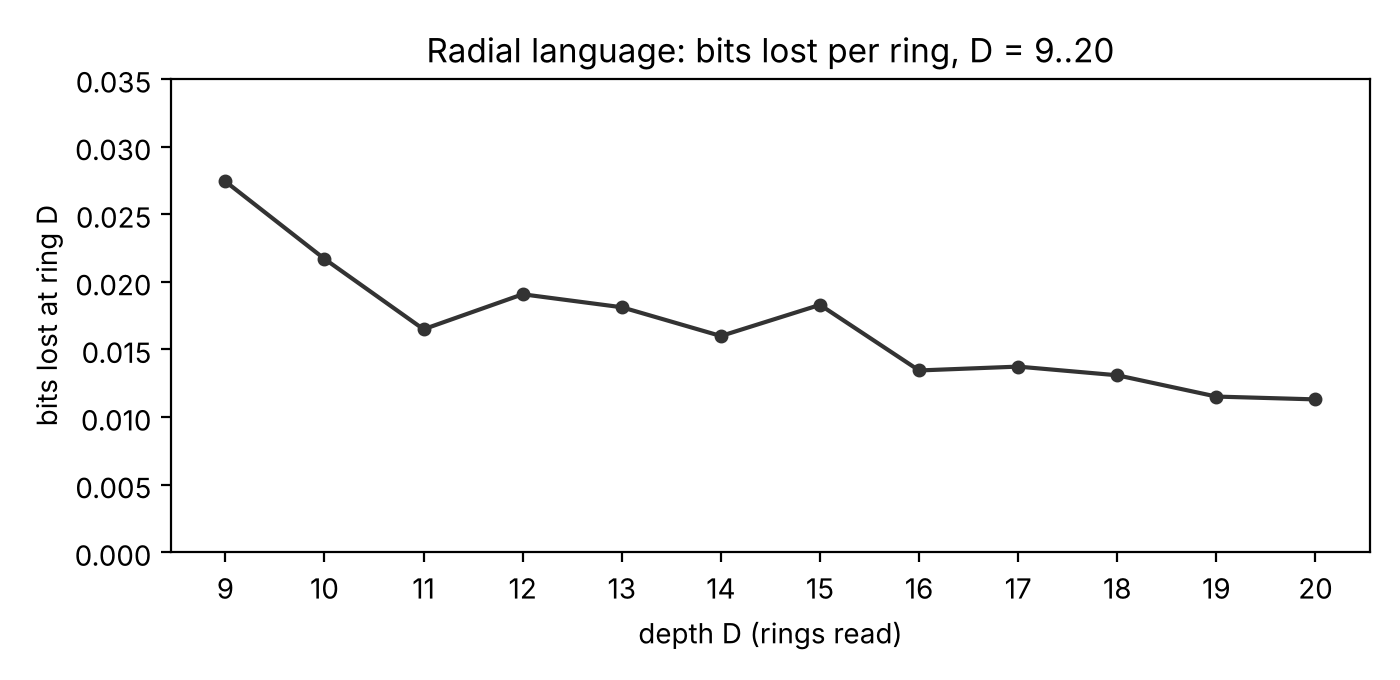

prior table rerun: R_10..R_16 = 924 ... 55122, H_angle(16) = 14.951476: RUNS  


In [17]:
def ring_np(L):
    x = np.arange(1 << L, dtype=np.int64); j = rev_np(x, L); p = np.where(j == x, x ^ ((1 << L) - 1), j)
    rp = x[x < p]; N = 1 << L; M = N >> 1; R = np.empty(N, dtype=np.int64)
    R[:M] = rp; R[N - 1 - np.arange(M)] = p[rp]
    if M > 1: R[M - 1], R[M] = R[M], R[M - 1]
    return R
def tape_np(L):
    R = ring_np(L); sh = np.arange(L - 1, -1, -1, dtype=np.int64)
    return ((R[:, None] >> sh[None, :]) & 1).astype(np.uint8).ravel()
def radial_counts(Dmax):
    lcm = 1
    for L in range(1, Dmax + 1): lcm = lcm * L // math.gcd(lcm, L)
    Dn = lcm << Dmax; bounds = np.zeros(1, dtype=np.int64); tp = {}; out = []
    for D in range(1, Dmax + 1):
        bounds = np.union1d(bounds, np.arange(D << D, dtype=np.int64) * (Dn // (D << D))); tp[D] = tape_np(D)
        prof = np.zeros(len(bounds), dtype=np.int64)
        for L in range(1, D + 1): prof = (prof << 1) | tp[L][bounds // (Dn // (L << L))]
        uq, inv = np.unique(prof, return_inverse=True)
        wid = np.diff(np.append(bounds, Dn)).astype(np.float64) / Dn
        meas = np.bincount(inv, weights=wid)
        out.append((D, len(uq), float(-(meas * np.log2(meas)).sum())))
    return out
RD = radial_counts(16)
for D, r, H in RD[8:]: print(f'D={D:2d}  R_D={r:7d}  deficit D-log2 R_D={D - math.log2(r):.5f}  H_angle={H:.6f}')
EXT = {17: 109200, 18: 216428, 19: 429416, 20: 852130}   # radial_counts(20), run outside the notebook (about 2 minutes, 2 GB)
print('extension, same function:', ', '.join(f'R_{D}={r}' for D, r in EXT.items()))
allR = {D: r for D, r, _ in RD}; allR.update(EXT)
Ds = sorted(allR); dfc = [D - math.log2(allR[D]) for D in Ds]
steps = [dfc[i] - dfc[i - 1] for i in range(1, len(Ds))]
print('deficit added per ring, D=11..20:', [round(s, 5) for s in steps[9:]])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(Ds[8:], steps[7:], 'o-', color='#333333', ms=4)
ax.set_xticks(Ds[8:]); ax.set_xlabel('depth D (rings read)'); ax.set_ylabel('bits lost at ring D')
ax.set_title('Radial language: bits lost per ring, D = 9..20'); ax.set_ylim(0, 0.035)
plt.tight_layout(); plt.savefig('figures/fig_radial.png', dpi=200); plt.close(); display(Image('figures/fig_radial.png', width=900))
mark('prior table rerun: R_10..R_16 = 924 ... 55122, H_angle(16) = 14.951476',
     [r for _, r, _ in RD[9:16]] == [924, 1827, 3606, 7122, 14087, 27819, 55122] and abs(RD[15][2] - 14.951476) < 1e-6)

## Route 11. Prior results, re-run on this compiler

**Algorithm.** Take the results supplied by the earlier sessions (the pad-law range, the residual alphabet, the byte codec, the 01 ray) and run them through the folded square. Each is a corollary of one picture: the pad-law edge is the centre of the diagonal, the residual is the XOR distance $d=f\oplus J(g)$ written as $d\|J(d)$, and the 01 ray is the apex corner.

In [18]:
# pad law: W_{L+2}(j) = 1 W_L(j) 1 for 0 <= j < K_L, first failure at K_L
def W(L, j): return ring(L)[(1 << (L - 1)) + j]
ok = True; rows = []
for L in range(2, 12):
    K = 1 + (2 ** (L - 2) - 2 ** ((L - 1) // 2)) // 2
    holds = all(W(L + 2, j) == (1 << (L + 1)) | (W(L, j) << 1) | 1 for j in range(K))
    fails = W(L + 2, K) != (1 << (L + 1)) | (W(L, K) << 1) | 1
    ok &= holds and fails; rows.append((L, K))
mark('prior: pad-law range K_L = 1 + (2^(L-2) - 2^ceil((L-2)/2))/2 and its first failure, L=2..11', ok, str(rows))
# residual alphabet = XOR distance from the diagonal
ok = True
for L in range(2, 15):
    img = {x ^ P(x, L) for x in range(1 << L)}; m = L // 2
    ok &= len(img) == (2 ** m - 1 if L % 2 == 0 else 2 ** m)
mark('prior: residual alphabet 2^m - 1 (even), 2^m (odd), L=2..14', ok)
# byte codec through the merge at width 17
def enc(b): return int(format(b, '08b')[::-1], 2)           # payload -> address (8-bit reversal)
def dec(r): return 0 if r == (1 << 17) - 1 else r >> 9
ok = all(dec(word_at(17, enc(b)) ^ P(word_at(17, enc(b)), 17)) == b for b in range(256))
mark('prior: every byte survives the merge at width 17 (smallest width with 256 residuals)', ok)
# the 01 ray: 1^k 0 1^(k+1), residual 0^k 11 0^k, sitting just right of the seam
ok = True; a, L = 1, 2
for k in range(1, 40):
    a = F(a, L); L += 2
    ok &= bits(a, L) == '1' * k + '0' + '1' * (k + 1) and bits(a ^ P(a, L), L) == '0' * k + '11' + '0' * k and ring(L)[1 << (L - 1)] == a if L <= 14 else bits(a, L) == '1' * k + '0' + '1' * (k + 1)
mark('prior: 01 ray 1^k 0 1^(k+1) with residual 0^k 11 0^k, right of the seam', ok)
# the tent: what the parabola leaves in the front half is half the palindromes, folded at the middle of the diagonal
ok = all(Fr(Q(f, n)) - (Fr(f * 2 ** n) - Fr(f * f, 2)) == Fr(min(f, 2 ** n - f), 2) for n in range(1, 12) for f in range(2 ** n))
mark('tent: Q(f) - (f 2^n - f^2/2) = min(f, 2^n - f)/2 exactly', ok)

prior: pad-law range K_L = 1 + (2^(L-2) - 2^ceil((L-2)/2))/2 and its first failure, L=2..11: RUNS  [(2, 1), (3, 1), (4, 2), (5, 3), (6, 7), (7, 13), (8, 29), (9, 57), (10, 121), (11, 241)]
prior: residual alphabet 2^m - 1 (even), 2^m (odd), L=2..14: RUNS  
prior: every byte survives the merge at width 17 (smallest width with 256 residuals): RUNS  
prior: 01 ray 1^k 0 1^(k+1) with residual 0^k 11 0^k, right of the seam: RUNS  
tent: Q(f) - (f 2^n - f^2/2) = min(f, 2^n - f)/2 exactly: RUNS  


## The map

Each route handed the next one the piece it needed. Drawn as a dependency chain, the routes are one program.

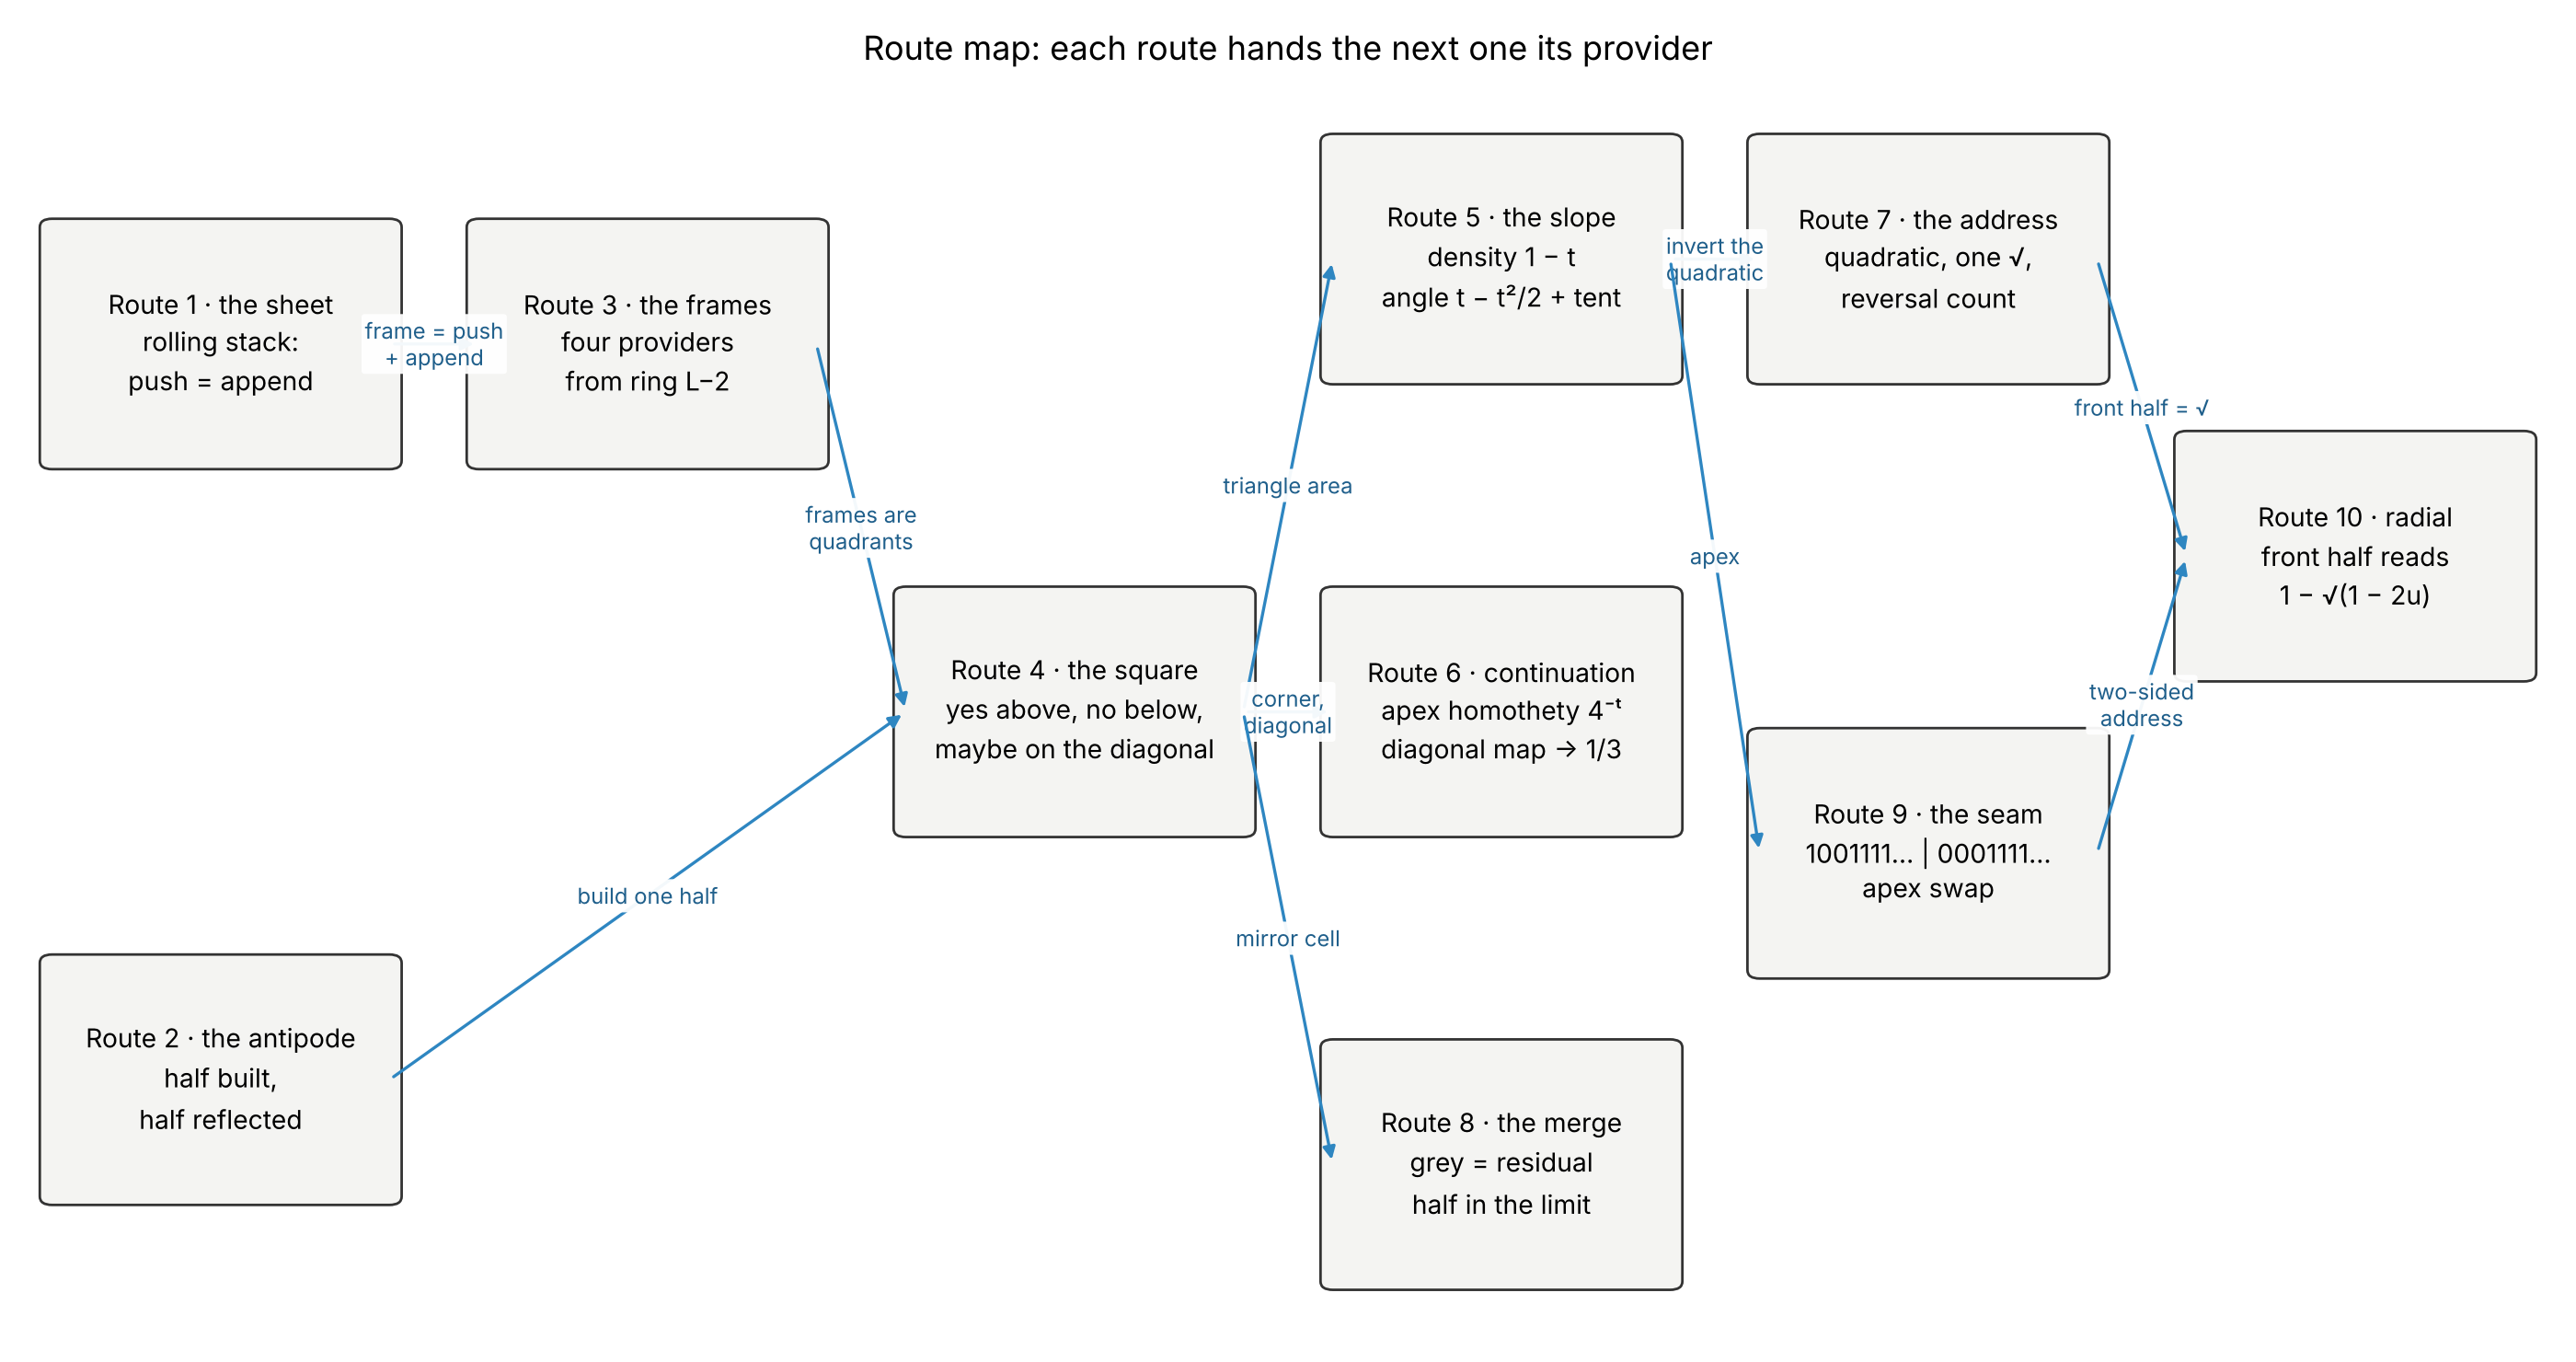

saved figures/fig_map.png


In [19]:
from matplotlib.patches import FancyBboxPatch
BW, BH = 0.166, 0.165
nodes = {
    'R1': (0.09, 0.78, 'Route 1 · the sheet\nrolling stack:\npush = append'),
    'R2': (0.09, 0.26, 'Route 2 · the antipode\nhalf built,\nhalf reflected'),
    'R3': (0.30, 0.78, 'Route 3 · the frames\nfour providers\nfrom ring L−2'),
    'R4': (0.51, 0.52, 'Route 4 · the square\nyes above, no below,\nmaybe on the diagonal'),
    'R5': (0.72, 0.84, 'Route 5 · the slope\ndensity 1 − t\nangle t − t²/2 + tent'),
    'R6': (0.72, 0.52, 'Route 6 · continuation\napex homothety 4⁻ᵗ\ndiagonal map → 1/3'),
    'R8': (0.72, 0.20, 'Route 8 · the merge\ngrey = residual\nhalf in the limit'),
    'R7': (0.93, 0.84, 'Route 7 · the address\nquadratic, one √,\nreversal count'),
    'R9': (0.93, 0.42, 'Route 9 · the seam\n1001111… | 0001111…\napex swap'),
    'R10': (1.14, 0.63, 'Route 10 · radial\nfront half reads\n1 − √(1 − 2u)'),
}
edges = [('R1', 'R3', 'frame = push\n+ append'), ('R2', 'R4', 'build one half'), ('R3', 'R4', 'frames are\nquadrants'),
         ('R4', 'R5', 'triangle area'), ('R4', 'R6', 'corner,\ndiagonal'), ('R4', 'R8', 'mirror cell'),
         ('R5', 'R7', 'invert the\nquadratic'), ('R5', 'R9', 'apex'), ('R7', 'R10', 'front half = √'), ('R9', 'R10', 'two-sided\naddress')]
fig, ax = plt.subplots(figsize=(14, 7.4)); ax.set_xlim(-0.005, 1.235); ax.set_ylim(0.08, 0.97); ax.axis('off')
for k, (x, y, t) in nodes.items():
    ax.add_patch(FancyBboxPatch((x - BW / 2, y - BH / 2), BW, BH, boxstyle='round,pad=0.006', fc='#f4f4f2', ec='#333333', lw=1))
    ax.text(x, y, t, ha='center', va='center', fontsize=10.2, linespacing=1.25)
for a, b_, lab in edges:
    x1, y1, _ = nodes[a]; x2, y2, _ = nodes[b_]
    p1 = (x1 + BW / 2, y1); p2 = (x2 - BW / 2, y2)
    ax.annotate('', xy=p2, xytext=p1, arrowprops=dict(arrowstyle='-|>', color='#2e86c1', lw=1.2, shrinkA=2, shrinkB=2))
    ax.text((p1[0] + p2[0]) / 2, (p1[1] + p2[1]) / 2, lab, ha='center', va='center', fontsize=8.6, color='#1f5f8b',
            bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.95))
ax.set_title('Route map: each route hands the next one its provider', fontsize=13)
plt.tight_layout(); plt.savefig('figures/fig_map.png', dpi=200); plt.close(); display(Image('figures/fig_map.png', width=900))
print('saved figures/fig_map.png')

## Ledger

In [20]:
consts = [('rep density at value t', '1 - t'), ('angle of a rep of value t', 't - t^2/2'), ('start of the 11 frame', '3/8'),
          ('seam (apex)', '1/2'), ('complement attractor (value, angle)', '(1/3, 5/18)'), ('quarter-turn word value', '1 - 1/sqrt 2'),
          ('mean continuation depth', '1/3'), ('mean rep value', '1/3'), ('continuation share / root share', '1/4 / 3/4'),
          ('bit bias of a rep at depth h', '-/+ 2^-(h+2)'), ('every ring, light fraction', '1/2'),
          ('grey fraction of the merge', '1/2 + palindromes'), ('twisted slices', '2^ceil(L/2) / 2^L'),
          ('largest palindromic rep (pad-law edge)', '0 1^(L-2) 0'), ('seam profiles right | left', '1001111... | 0001111...')]
for a, b_ in consts: print(f'{a:42s} {b_}')
print()
for tag, st, d in LEDGER: print(f'{st:8s} {tag}' + (f'   [{d}]' if st == 'DEAD END' else ''))

rep density at value t                     1 - t
angle of a rep of value t                  t - t^2/2
start of the 11 frame                      3/8
seam (apex)                                1/2
complement attractor (value, angle)        (1/3, 5/18)
quarter-turn word value                    1 - 1/sqrt 2
mean continuation depth                    1/3
mean rep value                             1/3
continuation share / root share            1/4 / 3/4
bit bias of a rep at depth h               -/+ 2^-(h+2)
every ring, light fraction                 1/2
grey fraction of the merge                 1/2 + palindromes
twisted slices                             2^ceil(L/2) / 2^L
largest palindromic rep (pad-law edge)     0 1^(L-2) 0
seam profiles right | left                 1001111... | 0001111...

RUNS     S11 every cached cell of two_bit_circle.xlsx rebuilt
RUNS     S8a push-top = append-bottom on every tape and sheet, L=2..5
RUNS     S8b G_0(W) = B_0(W+3): the CCW column drops into the CW c